# Молекулярная динамика: единый лабораторный notebook

В документ последовательно объединены введение и пять лабораторных работ. Он полностью автономен: физическая модель, численные методы, эксперименты и анализ находятся в обычных Markdown- и Python-ячейках.

**Порядок работы:** выполните **Runtime → Run all**. По умолчанию каждая работа использует `MODE = 'DEMO'`. Для полного эксперимента измените режим на `FULL` в конфигурационной ячейке соответствующего раздела и перезапустите документ.

## Содержание

1. Введение в Jupyter и молекулярную динамику
2. Периодические границы
3. Установление равновесия
4. Углеродные стенки
5. Фазовый переход
6. Неопределённость и чувствительность

## Общее вычислительное ядро

Этот код используется всеми лабораторными работами и поэтому приведён один раз. Блоки идут от физических констант к силам, интегратору, визуализации и методам анализа. Крупные реализации свёрнуты по умолчанию, но остаются обычными редактируемыми ячейками.

In [1]:
from pathlib import Path

# В Colab это /content; локально — каталог, из которого открыт notebook.
PROJECT_ROOT = Path.cwd()
print(f'Рабочий каталог: {PROJECT_ROOT}; результаты будут сохранены в output/')

Рабочий каталог: /home/poke/code/molecular_dynamics/notebooks; результаты будут сохранены в output/


#### Физические константы и параметры взаимодействия

Задаём единицы СИ, массу атома калия и параметры потенциалов K–K и K–C. Все энергии относятся к одной взаимодействующей паре, а не к молю.

In [2]:
"""Physical constants and the fixed material parameters of the model.

The simulation core uses SI units. Energies are per particle, not per mole.
"""

from __future__ import annotations

from dataclasses import dataclass
import math


AVOGADRO = 6.022_140_76e23  # 1/mol, exact
BOLTZMANN = 1.380_649e-23  # J/K, exact
ATOMIC_MASS_UNIT = 1.660_539_066_60e-27  # kg

KELVIN_OFFSET_CELSIUS = 273.15
TEMPERATURE_C = 900.0
TEMPERATURE_K = TEMPERATURE_C + KELVIN_OFFSET_CELSIUS

MASS_K = 39.0983 * ATOMIC_MASS_UNIT
SIGMA_K = 0.4250e-9  # m
EPSILON_K = 850.0 * BOLTZMANN  # J/particle

# UFF C_3 values are used only for the fixed diamond wall. UFF lists the
# minimum position x and well depth D; sigma=x/2**(1/6) maps that minimum to
# the conventional 12-6 LJ form used by this project.
SIGMA_C = (3.851e-10) / (2.0 ** (1.0 / 6.0))
EPSILON_C = 0.105 * 4184.0 / AVOGADRO  # 0.105 kcal/mol -> J/particle
SIGMA_KC = 0.5 * (SIGMA_K + SIGMA_C)
EPSILON_KC = math.sqrt(EPSILON_K * EPSILON_C)
DIAMOND_LATTICE_CONSTANT = 0.3567e-9  # m
WALL_SPACING = DIAMOND_LATTICE_CONSTANT / math.sqrt(2.0)

LAYER_THICKNESS = (1.0e-3 / (4.0 * AVOGADRO)) ** (1.0 / 3.0)


@dataclass(frozen=True)
class LJParameters:
    sigma: float
    epsilon: float

    def __post_init__(self) -> None:
        if self.sigma <= 0.0 or self.epsilon <= 0.0:
            raise ValueError("LJ sigma and epsilon must be positive")

    @property
    def r_min(self) -> float:
        return 2.0 ** (1.0 / 6.0) * self.sigma

    @property
    def timescale(self) -> float:
        return self.sigma * math.sqrt(MASS_K / self.epsilon)


K_LJ = LJParameters(SIGMA_K, EPSILON_K)
C_LJ = LJParameters(SIGMA_C, EPSILON_C)
KC_LJ = LJParameters(SIGMA_KC, EPSILON_KC)


#### Геометрия и параметры расчёта

Собираем размер области, шаг интегрирования, число частиц, граничные условия и диагностические допуски в одну проверяемую конфигурацию.

In [3]:
"""Configuration objects for the 2D MD engine."""

from __future__ import annotations

from dataclasses import dataclass, field
import math



@dataclass(frozen=True)
class Box:
    lx: float = 24.0e-9
    ly: float = 24.0e-9

    @property
    def area(self) -> float:
        return self.lx * self.ly


@dataclass(frozen=True)
class MDConfig:
    n_particles: int = 1035
    temperature: float = TEMPERATURE_K
    mass: float = MASS_K
    box: Box = field(default_factory=Box)
    lj: object = K_LJ
    cutoff_factor: float = 2.5
    dt: float = 1.0e-15
    periodic_x: bool = True
    periodic_y: bool = True
    remove_com: bool = True
    seed: int = 7
    force_backend: str = "bruteforce"
    wall_mode: str = "none"
    max_force_factor: float = 1.0e6
    max_relative_energy_drift: float = 5.0e-3

    @property
    def cutoff(self) -> float:
        return self.cutoff_factor * self.lj.sigma

    @property
    def degrees_of_freedom(self) -> int:
        removed = 2 if self.remove_com else 0
        return 2 * self.n_particles - removed

    def validate(self) -> None:
        if self.n_particles < 2:
            raise ValueError("At least two particles are required")
        if self.temperature <= 0.0 or self.mass <= 0.0 or self.dt <= 0.0:
            raise ValueError("temperature, mass, and dt must be positive")
        if self.cutoff_factor <= 0.0:
            raise ValueError("cutoff_factor must be positive")
        if self.periodic_x and self.cutoff >= self.box.lx / 2.0:
            raise ValueError("cutoff must be smaller than half the periodic x box")
        if self.periodic_y and self.cutoff >= self.box.ly / 2.0:
            raise ValueError("cutoff must be smaller than half the periodic y box")
        if self.degrees_of_freedom <= 0:
            raise ValueError("number of thermal degrees of freedom must be positive")
        if self.force_backend not in {"bruteforce", "cell_list"}:
            raise ValueError("force_backend must be 'bruteforce' or 'cell_list'")
        if self.wall_mode not in {"none", "all", "x"}:
            raise ValueError("wall_mode must be 'none', 'all', or 'x'")
        if self.wall_mode == "all" and (self.periodic_x or self.periodic_y):
            raise ValueError("all fixed walls require non-periodic x and y")
        if self.wall_mode == "x" and (self.periodic_x is True or self.periodic_y is False):
            raise ValueError("x-wall geometry requires x fixed and y periodic")
        if self.max_force_factor <= 0.0 or self.max_relative_energy_drift <= 0.0:
            raise ValueError("numerical safety thresholds must be positive")


def default_config(**overrides: object) -> MDConfig:
    values = {name: getattr(MDConfig(), name) for name in MDConfig.__dataclass_fields__}
    values.update(overrides)
    config = MDConfig(**values)
    config.validate()
    return config


#### Граничные условия

Реализуем периодическое заворачивание координат, minimum-image расстояние и отражение от непериодических границ.

In [4]:
"""Boundary and minimum-image operations for rectangular 2D boxes."""

from __future__ import annotations

import numpy as np



def minimum_image(
    displacement: np.ndarray,
    box: Box,
    periodic_x: bool = True,
    periodic_y: bool = True,
) -> np.ndarray:
    result = np.asarray(displacement, dtype=np.float64).copy()
    if periodic_x:
        result[..., 0] -= box.lx * np.round(result[..., 0] / box.lx)
    if periodic_y:
        result[..., 1] -= box.ly * np.round(result[..., 1] / box.ly)
    return result


def wrap_positions(
    positions: np.ndarray,
    box: Box,
    periodic_x: bool = True,
    periodic_y: bool = True,
) -> np.ndarray:
    wrapped = np.asarray(positions, dtype=np.float64).copy()
    if periodic_x:
        wrapped[:, 0] %= box.lx
    if periodic_y:
        wrapped[:, 1] %= box.ly
    return wrapped


def validate_positions_in_box(
    positions: np.ndarray,
    box: Box,
    periodic_x: bool = True,
    periodic_y: bool = True,
) -> None:
    """Reject crossing of a fixed boundary instead of silently clipping it."""
    values = np.asarray(positions)
    if not np.all(np.isfinite(values)):
        raise FloatingPointError("non-finite coordinates after integration")
    tolerance = 1.0e-15
    if not periodic_x and (
        np.any(values[:, 0] < -tolerance) or np.any(values[:, 0] > box.lx + tolerance)
    ):
        raise FloatingPointError("particle crossed fixed x boundary")
    if not periodic_y and (
        np.any(values[:, 1] < -tolerance) or np.any(values[:, 1] > box.ly + tolerance)
    ):
        raise FloatingPointError("particle crossed fixed y boundary")


#### Парный потенциал Леннарда — Джонса

Вычисляем энергию и производную LJ, затем обрезаем и сдвигаем энергию на радиусе cutoff. Проверка отдельно останавливает численно опасные сближения.

In [5]:
"""Analytic Lennard-Jones and truncated-shifted Lennard-Jones functions."""

from __future__ import annotations

from dataclasses import dataclass
import numpy as np



class NumericalInstabilityError(RuntimeError):
    """Raised when a pair distance is too small for a stable LJ evaluation."""


@dataclass(frozen=True)
class LJTS:
    parameters: LJParameters
    cutoff: float
    minimum_distance: float = 1.0e-15

    def __post_init__(self) -> None:
        if self.cutoff <= 0.0:
            raise ValueError("cutoff must be positive")
        if self.minimum_distance <= 0.0:
            raise ValueError("minimum_distance must be positive")

    def energy_and_radial_derivative(self, distance: float) -> tuple[float, float]:
        if not np.isfinite(distance) or distance < self.minimum_distance:
            raise NumericalInstabilityError(
                f"invalid pair distance r={distance:.6e} m"
            )
        if distance >= self.cutoff:
            return 0.0, 0.0

        u_lj, derivative = lj_energy_and_radial_derivative(distance, self.parameters)
        u_cut, _ = lj_energy_and_radial_derivative(self.cutoff, self.parameters)
        return u_lj - u_cut, derivative

    def force_on_i(self, displacement_i_from_j: np.ndarray) -> tuple[float, np.ndarray]:
        distance = float(np.linalg.norm(displacement_i_from_j))
        energy, derivative = self.energy_and_radial_derivative(distance)
        if derivative == 0.0:
            return energy, np.zeros(2, dtype=np.float64)
        # displacement is r_i-r_j; force is -grad_{r_i} U.
        force = -derivative * displacement_i_from_j / distance
        return energy, force


def lj_energy_and_radial_derivative(
    distance: float, parameters: LJParameters
) -> tuple[float, float]:
    """Return the unshifted LJ energy and dU/dr."""
    if not np.isfinite(distance) or distance <= 0.0:
        raise NumericalInstabilityError(f"invalid pair distance r={distance:.6e} m")
    sigma = parameters.sigma
    epsilon = parameters.epsilon
    sr6 = (sigma / distance) ** 6
    energy = 4.0 * epsilon * (sr6 * sr6 - sr6)
    derivative = 24.0 * epsilon / distance * (sr6 - 2.0 * sr6 * sr6)
    return energy, derivative


#### Начальные координаты и скорости

Частицы размещаются на слегка возмущённой решётке. Скорости выбираются из распределения Максвелла, затем удаляется движение центра масс и задаётся температура.

In [6]:
"""Reproducible initial coordinates and Maxwell-Boltzmann velocities."""

from __future__ import annotations

import numpy as np



def _stream_rng(config: MDConfig, stream: int) -> np.random.Generator:
    """Create one deterministic, independent stream for a state component."""
    streams = np.random.SeedSequence(config.seed).spawn(2)
    return np.random.default_rng(streams[stream])


def lattice_positions(
    config: MDConfig,
    jitter_fraction: float = 0.08,
    rng: np.random.Generator | None = None,
) -> np.ndarray:
    """Place particles on a near-uniform 2D lattice with reproducible jitter."""
    if not 0.0 <= jitter_fraction < 0.25:
        raise ValueError("jitter_fraction must be in [0, 0.25)")

    margin = 0.0
    if config.wall_mode in {"all", "x"}:
        margin = 0.75 * KC_LJ.r_min
    if config.wall_mode == "all":
        lower = np.array([margin, margin])
        upper = np.array([config.box.lx - margin, config.box.ly - margin])
    elif config.wall_mode == "x":
        lower = np.array([margin, 0.0])
        upper = np.array([config.box.lx - margin, config.box.ly])
    else:
        lower = np.zeros(2)
        upper = np.array([config.box.lx, config.box.ly])
    available = upper - lower
    n_x = int(np.ceil(np.sqrt(config.n_particles * available[0] / available[1])))
    n_y = int(np.ceil(config.n_particles / n_x))
    spacing_x = available[0] / n_x
    spacing_y = available[1] / n_y
    capacity = n_x * n_y
    # Evenly sample the flattened lattice instead of taking a contiguous
    # prefix, which would leave a visibly underfilled final row.
    selected = np.floor(
        (np.arange(config.n_particles, dtype=np.float64) + 0.5)
        * capacity
        / config.n_particles
    ).astype(np.intp)
    ix = selected % n_x
    iy = selected // n_x
    positions = np.column_stack(
        (lower[0] + (ix + 0.5) * spacing_x, lower[1] + (iy + 0.5) * spacing_y)
    ).astype(np.float64)

    if jitter_fraction:
        rng = _stream_rng(config, 0) if rng is None else rng
        jitter = rng.uniform(-jitter_fraction, jitter_fraction, positions.shape)
        positions[:, 0] += jitter[:, 0] * spacing_x
        positions[:, 1] += jitter[:, 1] * spacing_y
    return positions


def maxwell_boltzmann_velocities(
    config: MDConfig,
    rng: np.random.Generator | None = None,
) -> np.ndarray:
    """Generate 2D velocities, remove COM motion, and rescale to target T."""
    rng = _stream_rng(config, 1) if rng is None else rng
    scale = np.sqrt(BOLTZMANN * config.temperature / config.mass)
    velocities = rng.normal(0.0, scale, size=(config.n_particles, 2))
    if config.remove_com:
        velocities -= velocities.mean(axis=0)

    kinetic = 0.5 * config.mass * np.sum(velocities * velocities)
    measured = 2.0 * kinetic / (config.degrees_of_freedom * BOLTZMANN)
    if not np.isfinite(measured) or measured <= 0.0:
        raise FloatingPointError("invalid initial kinetic temperature")
    velocities *= np.sqrt(config.temperature / measured)
    return velocities


def initialize(config: MDConfig) -> tuple[np.ndarray, np.ndarray]:
    config.validate()
    position_seed, velocity_seed = np.random.SeedSequence(config.seed).spawn(2)
    return lattice_positions(
        config, rng=np.random.default_rng(position_seed)
    ), maxwell_boltzmann_velocities(
        config, rng=np.random.default_rng(velocity_seed)
    )


#### Измеряемые физические величины

Определяем кинетическую энергию, мгновенную температуру, двумерное вириальное давление и механическое давление на x-стенки.

In [7]:
"""Thermodynamic observables for a 2D system."""

from __future__ import annotations

import numpy as np



def kinetic_energy(velocities: np.ndarray, mass: float) -> float:
    return float(0.5 * mass * np.sum(np.asarray(velocities) ** 2))


def instantaneous_temperature(
    velocities: np.ndarray,
    mass: float,
    remove_com: bool = True,
) -> float:
    values = np.asarray(velocities, dtype=np.float64)
    if remove_com:
        values = values - values.mean(axis=0)
    dof = 2 * len(values) - (2 if remove_com else 0)
    return 2.0 * kinetic_energy(values, mass) / (dof * BOLTZMANN)


def pressure_2d(kinetic: float, virial: float, area: float) -> float:
    return (kinetic + 0.5 * virial) / area


def pressure_on_x_walls(
    wall_positions: np.ndarray,
    wall_reaction: np.ndarray,
    box_length_y: float,
) -> tuple[float, float, float]:
    """Return left, right, and mean mechanical pressure in N/m."""
    tolerance = max(1.0e-15, box_length_y * 1.0e-12)
    left = np.isclose(wall_positions[:, 0], 0.0, atol=tolerance)
    right = np.isclose(
        wall_positions[:, 0], np.max(wall_positions[:, 0]), atol=tolerance
    )
    left_pressure = abs(float(np.sum(wall_reaction[left, 0]))) / box_length_y
    right_pressure = abs(float(np.sum(wall_reaction[right, 0]))) / box_length_y
    return left_pressure, right_pressure, 0.5 * (left_pressure + right_pressure)


#### Геометрия углеродных стенок

Строим фиксированные ряды атомов углерода с шагом алмазной решётки. Эти атомы создают внешнее поле, но сами не интегрируются во времени.

In [8]:
"""Fixed one-layer diamond-carbon wall geometry."""

from __future__ import annotations

import numpy as np



def _line_positions(length: float) -> np.ndarray:
    count = max(2, int(np.floor(length / WALL_SPACING)) + 1)
    return np.linspace(0.0, length, count, dtype=np.float64)


def _periodic_line_positions(length: float) -> np.ndarray:
    count = max(1, int(np.floor(length / WALL_SPACING)))
    return np.arange(count, dtype=np.float64) * (length / count)


def diamond_wall_positions(box: Box, mode: str) -> np.ndarray:
    """Return one fixed C-atom line per required side.

    In this strictly 2D representation, (100) diamond surface order is
    represented by the in-plane spacing a/sqrt(2). Corner atoms are unique.
    """
    if mode not in {"all", "x"}:
        raise ValueError("wall mode must be 'all' or 'x'")
    atoms: set[tuple[float, float]] = set()
    y_values = _periodic_line_positions(box.ly) if mode == "x" else _line_positions(box.ly)
    x_values = _line_positions(box.lx)
    for y in y_values:
        atoms.add((0.0, float(y)))
        atoms.add((box.lx, float(y)))
    if mode == "all":
        for x in x_values:
            atoms.add((float(x), 0.0))
            atoms.add((float(x), box.ly))
    return np.asarray(sorted(atoms), dtype=np.float64)


#### Расчёт межатомных сил

Суммируем парные силы, потенциальную энергию и вириал. Для больших систем используется список пространственных ячеек; поддерживается и взаимодействие со стенками.

In [9]:
"""Reference O(N^2) pair-force calculation."""

from __future__ import annotations

import numpy as np



def compute_forces_bruteforce(
    positions: np.ndarray,
    box: Box,
    potential: LJTS,
    periodic_x: bool = True,
    periodic_y: bool = True,
) -> tuple[np.ndarray, float, float]:
    """Return forces, potential energy, and positive-repulsion virial.

    ``displacement = r_i-r_j`` and the returned pair force is force on i
    from j. The stored virial is ``sum(displacement dot force_i)`` so that
    the 2D pressure is ``(kinetic_energy + virial / 2) / area``.
    """
    coordinates = np.asarray(positions, dtype=np.float64)
    if coordinates.ndim != 2 or coordinates.shape[1] != 2:
        raise ValueError("positions must have shape (N, 2)")
    if not np.all(np.isfinite(coordinates)):
        raise FloatingPointError("non-finite coordinates")

    forces = np.zeros_like(coordinates)
    potential_energy = 0.0
    virial = 0.0
    for i in range(len(coordinates) - 1):
        for j in range(i + 1, len(coordinates)):
            displacement = minimum_image(
                coordinates[i] - coordinates[j],
                box,
                periodic_x=periodic_x,
                periodic_y=periodic_y,
            )
            energy, force_i = potential.force_on_i(displacement)
            forces[i] += force_i
            forces[j] -= force_i
            potential_energy += energy
            virial += float(np.dot(displacement, force_i))

    if not np.all(np.isfinite(forces)) or not np.isfinite(potential_energy):
        raise FloatingPointError("non-finite force or potential energy")
    return forces, potential_energy, virial


def compute_forces_cell_list(
    positions: np.ndarray,
    box: Box,
    potential: LJTS,
    periodic_x: bool = True,
    periodic_y: bool = True,
) -> tuple[np.ndarray, float, float]:
    """Cell-list version of the pair calculation.

    The cell width is chosen not smaller than the cutoff, so the 3x3
    neighboring-cell stencil is sufficient. Pair arithmetic is intentionally
    identical to the reference backend.
    """
    coordinates = np.asarray(positions, dtype=np.float64)
    if coordinates.ndim != 2 or coordinates.shape[1] != 2:
        raise ValueError("positions must have shape (N, 2)")
    if not np.all(np.isfinite(coordinates)):
        raise FloatingPointError("non-finite coordinates")

    lengths = np.array([box.lx, box.ly], dtype=np.float64)
    periodic = (periodic_x, periodic_y)
    n_cells = np.maximum(1, np.floor(lengths / potential.cutoff).astype(int))
    cell_width = lengths / n_cells
    cell_of_particle = np.floor(coordinates / cell_width).astype(int)
    for axis in range(2):
        cell_of_particle[:, axis] = np.clip(
            cell_of_particle[:, axis], 0, n_cells[axis] - 1
        )

    cells: dict[tuple[int, int], list[int]] = {}
    for particle, cell in enumerate(cell_of_particle):
        key = (int(cell[0]), int(cell[1]))
        cells.setdefault(key, []).append(particle)

    pair_i: list[int] = []
    pair_j: list[int] = []
    for i, cell in enumerate(cell_of_particle):
        neighbor_keys: set[tuple[int, int]] = set()
        for dx in (-1, 0, 1):
            for dy in (-1, 0, 1):
                candidate = [int(cell[0] + dx), int(cell[1] + dy)]
                valid = True
                for axis, is_periodic in enumerate(periodic):
                    if is_periodic:
                        candidate[axis] %= int(n_cells[axis])
                    elif not 0 <= candidate[axis] < n_cells[axis]:
                        valid = False
                if valid:
                    neighbor_keys.add((candidate[0], candidate[1]))

        for key in neighbor_keys:
            for j in cells.get(key, ()):
                if j <= i:
                    continue
                pair_i.append(i)
                pair_j.append(j)

    forces = np.zeros_like(coordinates)
    if pair_i:
        indices_i = np.asarray(pair_i, dtype=np.intp)
        indices_j = np.asarray(pair_j, dtype=np.intp)
        displacements = minimum_image(
            coordinates[indices_i] - coordinates[indices_j],
            box,
            periodic_x=periodic_x,
            periodic_y=periodic_y,
        )
        distances = np.linalg.norm(displacements, axis=1)
        active = distances < potential.cutoff
        if np.any(distances[active] < potential.minimum_distance):
            bad_distance = float(np.min(distances[active]))
            raise FloatingPointError(f"invalid pair distance r={bad_distance:.6e} m")
        if np.any(active):
            active_i = indices_i[active]
            active_j = indices_j[active]
            active_displacements = displacements[active]
            active_distances = distances[active]
            sigma = potential.parameters.sigma
            epsilon = potential.parameters.epsilon
            sr6 = (sigma / active_distances) ** 6
            sr6_cut = (sigma / potential.cutoff) ** 6
            u_cut = 4.0 * epsilon * (sr6_cut * sr6_cut - sr6_cut)
            pair_energy = 4.0 * epsilon * (sr6 * sr6 - sr6) - u_cut
            derivative = 24.0 * epsilon / active_distances * (sr6 - 2.0 * sr6 * sr6)
            pair_forces = -derivative[:, None] * active_displacements / active_distances[:, None]
            np.add.at(forces, active_i, pair_forces)
            np.add.at(forces, active_j, -pair_forces)
            potential_energy = float(np.sum(pair_energy))
            virial = float(np.sum(np.einsum("ij,ij->i", active_displacements, pair_forces)))
        else:
            potential_energy = 0.0
            virial = 0.0
    else:
        potential_energy = 0.0
        virial = 0.0

    if not np.all(np.isfinite(forces)) or not np.isfinite(potential_energy):
        raise FloatingPointError("non-finite force or potential energy")
    return forces, potential_energy, virial


def compute_forces(
    positions: np.ndarray,
    box: Box,
    potential: LJTS,
    periodic_x: bool = True,
    periodic_y: bool = True,
    backend: str = "bruteforce",
) -> tuple[np.ndarray, float, float]:
    if backend == "bruteforce":
        return compute_forces_bruteforce(
            positions, box, potential, periodic_x, periodic_y
        )
    if backend == "cell_list":
        return compute_forces_cell_list(
            positions, box, potential, periodic_x, periodic_y
        )
    raise ValueError(f"unknown force backend: {backend}")


def compute_forces_with_walls(
    positions: np.ndarray,
    box: Box,
    gas_potential: LJTS,
    wall_positions: np.ndarray,
    wall_potential: LJTS,
    periodic_x: bool,
    periodic_y: bool,
    backend: str = "cell_list",
) -> tuple[np.ndarray, float, float, np.ndarray]:
    """Gas-gas plus gas-fixed-wall interactions.

    ``wall_reaction`` is the force exerted by gas on each fixed wall atom.
    Wall-wall energy is omitted because fixed wall coordinates make it a
    constant irrelevant to gas dynamics.
    """
    gas_forces, gas_energy, gas_virial = compute_forces(
        positions,
        box,
        gas_potential,
        periodic_x,
        periodic_y,
        backend,
    )
    walls = np.asarray(wall_positions, dtype=np.float64)
    displacement = np.asarray(positions)[:, None, :] - walls[None, :, :]
    displacement = minimum_image(
        displacement, box, periodic_x=periodic_x, periodic_y=periodic_y
    )
    distances = np.linalg.norm(displacement, axis=2)
    active = distances < wall_potential.cutoff
    if np.any(distances[active] < wall_potential.minimum_distance):
        raise FloatingPointError("K atom overlaps a fixed carbon wall atom")

    pair_forces = np.zeros_like(displacement)
    pair_energy = 0.0
    wall_virial = 0.0
    if np.any(active):
        active_distances = distances[active]
        sigma = wall_potential.parameters.sigma
        epsilon = wall_potential.parameters.epsilon
        sr6 = (sigma / active_distances) ** 6
        sr6_cut = (sigma / wall_potential.cutoff) ** 6
        u_cut = 4.0 * epsilon * (sr6_cut * sr6_cut - sr6_cut)
        pair_energy = float(np.sum(4.0 * epsilon * (sr6 * sr6 - sr6) - u_cut))
        derivative = 24.0 * epsilon / active_distances * (sr6 - 2.0 * sr6 * sr6)
        pair_forces[active] = -derivative[:, None] * displacement[active] / active_distances[:, None]
        wall_virial = float(np.sum(displacement[active] * pair_forces[active]))

    gas_forces += np.sum(pair_forces, axis=1)
    wall_reaction = -np.sum(pair_forces, axis=0)
    total_energy = gas_energy + pair_energy
    total_virial = gas_virial + wall_virial
    if not np.all(np.isfinite(gas_forces)) or not np.isfinite(total_energy):
        raise FloatingPointError("non-finite wall force or energy")
    return gas_forces, total_energy, total_virial, wall_reaction


#### Интегрирование уравнений движения

Один шаг velocity Verlet последовательно обновляет координаты, силы и скорости. Есть варианты для периодической системы и системы с фиксированными стенками.

In [10]:
"""Time integration schemes."""

from __future__ import annotations

import numpy as np



def velocity_verlet_step(
    positions: np.ndarray,
    velocities: np.ndarray,
    forces: np.ndarray,
    config: MDConfig,
    potential: LJTS,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, float, float]:
    """Advance one NVE step and return new state plus U and virial."""
    acceleration = forces / config.mass
    new_positions = (
        positions + velocities * config.dt + 0.5 * acceleration * config.dt**2
    )
    new_positions = wrap_positions(
        new_positions,
        config.box,
        periodic_x=config.periodic_x,
        periodic_y=config.periodic_y,
    )
    validate_positions_in_box(
        new_positions, config.box, config.periodic_x, config.periodic_y
    )
    new_forces, potential_energy, virial = compute_forces(
        new_positions,
        config.box,
        potential,
        periodic_x=config.periodic_x,
        periodic_y=config.periodic_y,
        backend=config.force_backend,
    )
    new_acceleration = new_forces / config.mass
    new_velocities = velocities + 0.5 * (acceleration + new_acceleration) * config.dt
    return new_positions, new_velocities, new_forces, potential_energy, virial


def velocity_verlet_step_with_walls(
    positions: np.ndarray,
    velocities: np.ndarray,
    forces: np.ndarray,
    config: MDConfig,
    gas_potential: LJTS,
    wall_positions: np.ndarray,
    wall_potential: LJTS,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, float, float, np.ndarray]:
    """Velocity Verlet for mobile K atoms in a fixed external wall field."""
    acceleration = forces / config.mass
    new_positions = positions + velocities * config.dt + 0.5 * acceleration * config.dt**2
    new_positions = wrap_positions(
        new_positions,
        config.box,
        periodic_x=config.periodic_x,
        periodic_y=config.periodic_y,
    )
    validate_positions_in_box(
        new_positions, config.box, config.periodic_x, config.periodic_y
    )
    new_forces, potential_energy, virial, wall_reaction = compute_forces_with_walls(
        new_positions,
        config.box,
        gas_potential,
        wall_positions,
        wall_potential,
        periodic_x=config.periodic_x,
        periodic_y=config.periodic_y,
        backend=config.force_backend,
    )
    new_acceleration = new_forces / config.mass
    new_velocities = velocities + 0.5 * (acceleration + new_acceleration) * config.dt
    return (
        new_positions,
        new_velocities,
        new_forces,
        potential_energy,
        virial,
        wall_reaction,
    )


#### Движок молекулярной динамики

Объединяем инициализацию, силы, интегратор и наблюдаемые величины. `MDEngine` выполняет шаги, а `run_nve` сохраняет временные ряды и кадры траектории.

In [11]:
"""Small reference MD engine used by the tests and later experiments."""

from __future__ import annotations

from dataclasses import dataclass
import numpy as np



@dataclass
class MDState:
    positions: np.ndarray
    velocities: np.ndarray
    forces: np.ndarray
    potential_energy: float
    virial: float
    wall_reaction: np.ndarray | None = None
    step: int = 0

    @property
    def kinetic_energy(self) -> float:
        raise AttributeError("kinetic energy requires the engine mass")


class MDEngine:
    def __init__(self, config: MDConfig, positions: np.ndarray | None = None, velocities: np.ndarray | None = None):
        config.validate()
        self.config = config
        self.potential = LJTS(config.lj, config.cutoff)
        self.wall_positions = (
            diamond_wall_positions(config.box, config.wall_mode)
            if config.wall_mode != "none"
            else None
        )
        self.wall_potential = (
            LJTS(KC_LJ, 2.5 * KC_LJ.sigma)
            if self.wall_positions is not None
            else None
        )
        if positions is None or velocities is None:
            positions, velocities = initialize(config)
        self.state = self._make_state(positions, velocities)

    def _make_state(self, positions: np.ndarray, velocities: np.ndarray) -> MDState:
        if self.wall_positions is None:
            forces, energy, virial = compute_forces(
                positions,
                self.config.box,
                self.potential,
                periodic_x=self.config.periodic_x,
                periodic_y=self.config.periodic_y,
                backend=self.config.force_backend,
            )
            wall_reaction = None
        else:
            forces, energy, virial, wall_reaction = compute_forces_with_walls(
                positions,
                self.config.box,
                self.potential,
                self.wall_positions,
                self.wall_potential,
                periodic_x=self.config.periodic_x,
                periodic_y=self.config.periodic_y,
                backend=self.config.force_backend,
            )
        state = MDState(
            np.asarray(positions, dtype=np.float64).copy(),
            np.asarray(velocities, dtype=np.float64).copy(),
            forces,
            energy,
            virial,
            wall_reaction,
        )
        self._validate_force_scale(state.forces)
        return state

    def _validate_force_scale(self, forces: np.ndarray) -> None:
        scale = self.config.lj.epsilon / self.config.lj.sigma
        if self.wall_potential is not None:
            scale = max(scale, self.wall_potential.parameters.epsilon / self.wall_potential.parameters.sigma)
        limit = self.config.max_force_factor * scale
        maximum = float(np.max(np.linalg.norm(forces, axis=1)))
        if not np.isfinite(maximum) or maximum > limit:
            raise NumericalInstabilityError(
                f"force magnitude {maximum:.6e} N exceeds diagnostic limit {limit:.6e} N"
            )

    def step(self) -> dict[str, float]:
        state = self.state
        if self.wall_positions is None:
            positions, velocities, forces, potential, virial = velocity_verlet_step(
                state.positions,
                state.velocities,
                state.forces,
                self.config,
                self.potential,
            )
            wall_reaction = None
        else:
            (
                positions,
                velocities,
                forces,
                potential,
                virial,
                wall_reaction,
            ) = velocity_verlet_step_with_walls(
                state.positions,
                state.velocities,
                state.forces,
                self.config,
                self.potential,
                self.wall_positions,
                self.wall_potential,
            )
        state.positions = positions
        state.velocities = velocities
        state.forces = forces
        state.potential_energy = potential
        state.virial = virial
        state.wall_reaction = wall_reaction
        state.step += 1
        self._validate_force_scale(forces)
        kinetic = kinetic_energy(velocities, self.config.mass)
        observation = {
            "step": float(state.step),
            "kinetic_energy": kinetic,
            "potential_energy": potential,
            "total_energy": kinetic + potential,
            "temperature": instantaneous_temperature(
                velocities, self.config.mass, self.config.remove_com
            ),
            "pressure_2d": pressure_2d(kinetic, virial, self.config.box.area),
        }
        if wall_reaction is not None and self.config.wall_mode == "x":
            _, _, wall_pressure = pressure_on_x_walls(
                self.wall_positions, wall_reaction, self.config.box.ly
            )
            observation["pressure_wall_x"] = wall_pressure
        return observation


def run_nve(
    config: MDConfig,
    n_steps: int,
    sample_interval: int = 1,
    frame_interval: int = 20,
) -> tuple[dict[str, np.ndarray], np.ndarray]:
    """Run NVE and return sampled observables plus wrapped coordinate frames."""
    if n_steps <= 0 or sample_interval <= 0 or frame_interval <= 0:
        raise ValueError("step and sampling intervals must be positive")
    engine = MDEngine(config)
    rows: list[dict[str, float]] = []
    frames: list[np.ndarray] = []

    def record(observation: dict[str, float]) -> None:
        rows.append(observation | {"time": observation["step"] * config.dt})
        frames.append(engine.state.positions.copy())

    initial_kinetic = kinetic_energy(engine.state.velocities, config.mass)
    reference_energy = initial_kinetic + engine.state.potential_energy
    initial_observation = {
        "step": 0.0,
        "kinetic_energy": initial_kinetic,
        "potential_energy": engine.state.potential_energy,
        "total_energy": initial_kinetic + engine.state.potential_energy,
        "temperature": instantaneous_temperature(
            engine.state.velocities, config.mass, config.remove_com
        ),
        "pressure_2d": pressure_2d(
            initial_kinetic, engine.state.virial, config.box.area
        ),
    }
    if config.wall_mode == "x":
        _, _, initial_observation["pressure_wall_x"] = pressure_on_x_walls(
            engine.wall_positions, engine.state.wall_reaction, config.box.ly
        )
    record(initial_observation)
    for step in range(1, n_steps + 1):
        observation = engine.step()
        relative_drift = abs(observation["total_energy"] - reference_energy) / max(
            abs(reference_energy), 1.0e-30
        )
        if relative_drift > config.max_relative_energy_drift:
            raise NumericalInstabilityError(
                f"relative NVE energy drift {relative_drift:.6e} exceeds "
                f"limit {config.max_relative_energy_drift:.6e}"
            )
        if step % sample_interval == 0:
            rows.append(observation | {"time": step * config.dt})
        if step % frame_interval == 0:
            frames.append(engine.state.positions.copy())

    history = {
        key: np.asarray([row[key] for row in rows], dtype=np.float64)
        for key in rows[0]
    }
    return history, np.asarray(frames, dtype=np.float64)


#### Графики и анимации

Функции Matplotlib строят диагностические графики и сохраняют GIF-анимации. Этот блок не участвует в вычислении сил.

In [12]:
"""Matplotlib output for trajectories and observables."""

from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
import numpy as np


J_TO_EV = 1.0 / 1.602_176_634e-19


def save_task1_plots(
    history: dict[str, np.ndarray],
    output_dir: Path,
    ideal_pressure_2d: float | None = None,
) -> None:
    output_dir.mkdir(parents=True, exist_ok=True)
    time_ps = history["time"] * 1.0e12
    plots = [
        ("kinetic_energy", "Kinetic energy", "energy (10^-18 J)", 1.0e18),
        ("potential_energy", "Potential energy", "energy (10^-18 J)", 1.0e18),
        ("total_energy", "Total energy", "energy (10^-18 J)", 1.0e18),
        ("temperature", "Instantaneous temperature", "temperature (K)", 1.0),
        ("pressure_2d", "Instantaneous 2D pressure", "pressure (N/m)", 1.0),
    ]
    for key, title, ylabel, scale in plots:
        figure, axis = plt.subplots(figsize=(7, 4))
        axis.plot(time_ps, history[key] * scale, label=key.replace("_", " "))
        if key == "pressure_2d" and ideal_pressure_2d is not None:
            axis.axhline(
                ideal_pressure_2d,
                color="tab:red",
                linestyle="--",
                label="ideal-gas reference",
            )
        axis.set_title(title)
        axis.set_xlabel("time (ps)")
        axis.set_ylabel(ylabel)
        axis.legend()
        axis.grid(alpha=0.25)
        figure.tight_layout()
        figure.savefig(output_dir / f"{key}_vs_time.png", dpi=150)
        plt.close(figure)

    figure, axis = plt.subplots(figsize=(7, 4))
    for key, label in (
        ("total_energy", "total"),
        ("kinetic_energy", "kinetic"),
        ("potential_energy", "potential"),
    ):
        axis.plot(time_ps, history[key] * 1.0e18, label=label)
    axis.set_title("Energy components")
    axis.set_xlabel("time (ps)")
    axis.set_ylabel("energy (10^-18 J)")
    axis.legend()
    axis.grid(alpha=0.25)
    figure.tight_layout()
    figure.savefig(output_dir / "energy_components_vs_time.png", dpi=150)
    plt.close(figure)

    initial_energy = history["total_energy"][0]
    relative_deviation = (
        history["total_energy"] - initial_energy
    ) / max(abs(initial_energy), 1.0e-30)
    figure, axis = plt.subplots(figsize=(7, 4))
    axis.plot(time_ps, relative_deviation, label="(E-E0)/|E0|")
    axis.axhline(0.0, color="black", linewidth=0.8)
    axis.set_title("Relative total-energy deviation")
    axis.set_xlabel("time (ps)")
    axis.set_ylabel("relative energy deviation")
    axis.legend()
    axis.grid(alpha=0.25)
    figure.tight_layout()
    figure.savefig(output_dir / "relative_energy_deviation_vs_time.png", dpi=150)
    plt.close(figure)


def save_task1_animation(
    frames: np.ndarray,
    box_length: float,
    output_path: Path,
    interval_ms: int = 40,
) -> None:
    if len(frames) == 0:
        raise ValueError("at least one frame is required")
    output_path.parent.mkdir(parents=True, exist_ok=True)
    figure, axis = plt.subplots(figsize=(6, 6))
    scatter = axis.scatter(frames[0, :, 0] * 1e9, frames[0, :, 1] * 1e9, s=8)
    axis.set_xlim(0.0, box_length * 1e9)
    axis.set_ylim(0.0, box_length * 1e9)
    axis.set_aspect("equal")
    axis.set_xlabel("x (nm)")
    axis.set_ylabel("y (nm)")
    axis.set_title("2D potassium gas: periodic NVE")

    def update(frame: np.ndarray):
        scatter.set_offsets(frame * 1e9)
        return (scatter,)

    animation = FuncAnimation(
        figure, update, frames=frames, interval=interval_ms, blit=True
    )
    animation.save(output_path, writer=PillowWriter(fps=max(1, 1000 // interval_ms)))
    plt.close(figure)


def save_equilibrium_pressure_plot(
    history: dict[str, np.ndarray],
    equilibration_index: int,
    equilibrium_mean: float,
    output_path: Path,
) -> None:
    output_path.parent.mkdir(parents=True, exist_ok=True)
    time_ps = history["time"] * 1e12
    pressure = history["pressure_2d"]
    figure, axis = plt.subplots(figsize=(8, 4.5))
    axis.plot(time_ps, pressure, lw=0.8, label="instantaneous P")
    axis.axvline(
        time_ps[equilibration_index],
        color="tab:red",
        ls="--",
        label="equilibration point",
    )
    axis.axhline(
        equilibrium_mean,
        color="tab:green",
        ls="-",
        label="equilibrium mean",
    )
    axis.set_title("Equilibrium pressure detection")
    axis.set_xlabel("time (ps)")
    axis.set_ylabel("2D pressure (N/m)")
    axis.legend()
    axis.grid(alpha=0.25)
    figure.tight_layout()
    figure.savefig(output_path, dpi=150)
    plt.close(figure)


def save_wall_animation(
    frames: np.ndarray,
    wall_positions: np.ndarray,
    box_length_x: float,
    box_length_y: float,
    output_path: Path,
    interval_ms: int = 40,
) -> None:
    output_path.parent.mkdir(parents=True, exist_ok=True)
    figure, axis = plt.subplots(figsize=(6, 6))
    gas = axis.scatter(frames[0, :, 0] * 1e9, frames[0, :, 1] * 1e9, s=8, label="K")
    axis.scatter(
        wall_positions[:, 0] * 1e9,
        wall_positions[:, 1] * 1e9,
        s=16,
        color="black",
        label="fixed C wall",
    )
    axis.set_xlim(0.0, box_length_x * 1e9)
    axis.set_ylim(0.0, box_length_y * 1e9)
    axis.set_aspect("equal")
    axis.set_xlabel("x (nm)")
    axis.set_ylabel("y (nm)")
    axis.set_title("2D potassium gas with fixed carbon walls")
    axis.legend()

    def update(frame: np.ndarray):
        gas.set_offsets(frame * 1e9)
        return (gas,)

    animation = FuncAnimation(
        figure, update, frames=frames, interval=interval_ms, blit=True
    )
    animation.save(output_path, writer=PillowWriter(fps=max(1, 1000 // interval_ms)))
    plt.close(figure)


def save_phase_plot(
    temperatures: np.ndarray,
    mean_susceptibility: np.ndarray,
    transition_temperature: float,
    output_path: Path,
) -> None:
    output_path.parent.mkdir(parents=True, exist_ok=True)
    figure, axis = plt.subplots(figsize=(7, 4.5))
    axis.plot(temperatures, mean_susceptibility, "o-", label="cluster susceptibility")
    axis.axvline(
        transition_temperature,
        color="tab:red",
        ls="--",
        label=f"maximum: {transition_temperature:.1f} K",
    )
    axis.set_xlabel("temperature (K)")
    axis.set_ylabel("N Var(largest-cluster fraction)")
    axis.set_title("Finite-system gas-to-condensed crossover")
    axis.legend()
    axis.grid(alpha=0.25)
    figure.tight_layout()
    figure.savefig(output_path, dpi=150)
    plt.close(figure)


def save_uq_plots(
    results: list[dict[str, float]],
    coefficients: dict[str, float],
    uncertainty: dict[str, float | np.ndarray],
    output_dir: Path,
) -> None:
    output_dir.mkdir(parents=True, exist_ok=True)
    observed = np.asarray([row["P_eq"] for row in results])
    predicted = np.asarray(coefficients["predicted"])
    figure, axis = plt.subplots(figsize=(6, 5))
    axis.scatter(predicted, observed, label="DOE simulations")
    low = min(np.min(predicted), np.min(observed))
    high = max(np.max(predicted), np.max(observed))
    axis.plot([low, high], [low, high], "k--", label="ideal fit")
    axis.set_xlabel("surrogate P (N/m)")
    axis.set_ylabel("MD P_eq (N/m)")
    axis.set_title("Linear surrogate validation")
    axis.legend()
    axis.grid(alpha=0.25)
    figure.tight_layout()
    figure.savefig(output_dir / "regression_comparison.png", dpi=150)
    plt.close(figure)

    figure, axis = plt.subplots(figsize=(7, 4.5))
    axis.hist(uncertainty["samples"], bins=50, density=True, alpha=0.8)
    axis.set_xlabel("surrogate pressure P (N/m)")
    axis.set_ylabel("density")
    axis.set_title("Propagated T/N uncertainty")
    axis.grid(alpha=0.25)
    figure.tight_layout()
    figure.savefig(output_dir / "uq_pressure_distribution.png", dpi=150)
    plt.close(figure)

    figure, axis = plt.subplots(figsize=(7, 4.5))
    temperatures = np.asarray([row["T"] for row in results])
    particles = np.asarray([row["N"] for row in results])
    scatter = axis.scatter(temperatures, particles, c=observed, cmap="viridis")
    figure.colorbar(scatter, ax=axis, label="P_eq (N/m)")
    axis.set_xlabel("temperature (K)")
    axis.set_ylabel("number of particles N")
    axis.set_title("DOE inputs and simulated pressure")
    axis.grid(alpha=0.25)
    figure.tight_layout()
    figure.savefig(output_dir / "uq_input_pressure_scatter.png", dpi=150)
    plt.close(figure)


#### Критерий установления равновесия

Временной ряд делится на блоки. Сравнение средних соседних участков даёт воспроизводимый индекс burn-in и статистику после него.

In [13]:
"""Numerical burn-in detection and block statistics."""

from __future__ import annotations

from dataclasses import dataclass
import numpy as np


@dataclass(frozen=True)
class EquilibriumStatistics:
    start_index: int
    start_step: int
    mean: float
    std: float
    sem: float
    n_samples: int


def find_equilibration_index(
    steps: np.ndarray,
    temperatures: np.ndarray,
    pressures: np.ndarray,
    ideal_pressure: float,
    block_size: int = 2000,
    comparison_blocks: int = 5,
    temperature_tolerance: float = 0.02,
    pressure_tolerance: float = 0.05,
    consecutive: int = 3,
) -> int:
    """Return the first sample index satisfying the fixed block criterion."""
    if block_size <= 0 or comparison_blocks <= 0 or consecutive <= 0:
        raise ValueError("block parameters must be positive")
    n = len(steps)
    window_length = 2 * comparison_blocks * block_size
    required = window_length + (consecutive - 1) * block_size
    if n < required:
        raise ValueError(
            f"at least {required} samples are required for equilibration detection"
        )

    pressure_scale = max(abs(ideal_pressure), 1.0e-30)
    run_length = consecutive
    for start in range(0, n - required + 1, block_size):
        old_slice = slice(start, start + comparison_blocks * block_size)
        new_start = old_slice.stop
        new_slice = slice(new_start, new_start + comparison_blocks * block_size)
        old_temperature = float(np.mean(temperatures[old_slice]))
        new_temperature = float(np.mean(temperatures[new_slice]))
        old_pressure = float(np.mean(pressures[old_slice]))
        new_pressure = float(np.mean(pressures[new_slice]))
        temperature_ok = (
            abs(new_temperature - old_temperature) / max(abs(new_temperature), 1.0e-30)
            < temperature_tolerance
        )
        pressure_ok = (
            abs(new_pressure - old_pressure) / pressure_scale < pressure_tolerance
        )
        if temperature_ok and pressure_ok:
            run_length -= 1
            if run_length == 0:
                return new_start
        else:
            run_length = consecutive
    raise ValueError("equilibration criterion was not met in the supplied trajectory")


def block_statistics(values: np.ndarray, start_index: int, block_size: int = 2000) -> EquilibriumStatistics:
    """Compute mean, standard deviation, and block-based SEM after burn-in."""
    values = np.asarray(values, dtype=np.float64)
    post = values[start_index:]
    if len(post) < 2:
        raise ValueError("at least two post-equilibration samples are required")
    std = float(np.std(post, ddof=1))
    blocks = len(post) // max(1, block_size)
    if blocks >= 2:
        block_means = np.mean(post[: blocks * block_size].reshape(blocks, block_size), axis=1)
        sem = float(np.std(block_means, ddof=1) / np.sqrt(blocks))
    else:
        sem = float(std / np.sqrt(len(post)))
    return EquilibriumStatistics(
        start_index=start_index,
        start_step=-1,
        mean=float(np.mean(post)),
        std=std,
        sem=sem,
        n_samples=len(post),
    )


#### Кластерные признаки фазового перехода

Частицы связываются по пороговому расстоянию с учётом границ. Размер крупнейшего кластера и его восприимчивость служат индикаторами конечносистемного перехода.

In [14]:
"""Finite-system diagnostics for the gas-to-condensed crossover."""

from __future__ import annotations

import numpy as np



def largest_cluster_fraction(
    positions: np.ndarray,
    box: Box,
    link_distance: float,
    periodic_x: bool = False,
    periodic_y: bool = True,
) -> float:
    """Return the largest connected-component fraction by a distance link."""
    n = len(positions)
    parents = np.arange(n)

    def find(index: int) -> int:
        while parents[index] != index:
            parents[index] = parents[parents[index]]
            index = parents[index]
        return index

    def union(first: int, second: int) -> None:
        root_first, root_second = find(first), find(second)
        if root_first != root_second:
            parents[root_second] = root_first

    for i in range(n - 1):
        displacement = positions[i] - positions[i + 1 :]
        displacement = minimum_image(
            displacement, box, periodic_x=periodic_x, periodic_y=periodic_y
        )
        close = np.flatnonzero(np.linalg.norm(displacement, axis=1) < link_distance)
        for offset in close:
            union(i, i + 1 + int(offset))

    counts = np.bincount([find(index) for index in range(n)], minlength=n)
    return float(np.max(counts) / n)


def cluster_susceptibility(fractions: np.ndarray, n_particles: int) -> float:
    values = np.asarray(fractions, dtype=np.float64)
    return float(n_particles * np.var(values))


def radial_distribution_2d(
    snapshots: np.ndarray,
    box: Box,
    r_max: float,
    bins: int = 100,
    periodic_x: bool = False,
    periodic_y: bool = True,
) -> tuple[np.ndarray, np.ndarray]:
    """Estimate a pair-distance histogram normalized as a bulk 2D g(r).

    For fixed-wall systems this is a diagnostic rather than a homogeneous-bulk
    thermodynamic estimator; wall inhomogeneity is reported separately.
    """
    edges = np.linspace(0.0, r_max, bins + 1)
    counts = np.zeros(bins, dtype=np.float64)
    n_snapshots = len(snapshots)
    if n_snapshots == 0:
        return 0.5 * (edges[1:] + edges[:-1]), counts
    n_particles = snapshots.shape[1]
    for positions in snapshots:
        for i in range(n_particles - 1):
            displacement = positions[i] - positions[i + 1 :]
            displacement = minimum_image(
                displacement, box, periodic_x=periodic_x, periodic_y=periodic_y
            )
            counts += np.histogram(np.linalg.norm(displacement, axis=1), edges)[0]
    radii = 0.5 * (edges[1:] + edges[:-1])
    shell_area = np.pi * (edges[1:] ** 2 - edges[:-1] ** 2)
    ideal_unordered = n_snapshots * n_particles * (n_particles - 1) / (2.0 * box.area)
    g_r = counts / (ideal_unordered * shell_area)
    return radii, g_r


#### Неопределённость и суррогатная модель

Для точки DOE запускаем MD и оцениваем давление, затем подгоняем линейную модель P(T,N) и переносим диапазоны входов методом Monte Carlo.

In [15]:
"""Non-intrusive uncertainty quantification around the Task 4 model."""

from __future__ import annotations

from dataclasses import replace
from typing import Any

import numpy as np



def run_simulation(
    temperature: float,
    n_particles: int,
    config: MDConfig,
    equilibration_steps: int = 2000,
    production_steps: int = 4000,
    sample_interval: int = 20,
) -> dict[str, float]:
    """Run the unchanged MD engine for one UQ input pair."""
    run_config = replace(
        config, temperature=float(temperature), n_particles=int(n_particles)
    )
    engine = MDEngine(run_config)
    for step in range(equilibration_steps):
        engine.step()
        if (step + 1) % 10 == 0:
            measured = instantaneous_temperature(
                engine.state.velocities, run_config.mass, run_config.remove_com
            )
            engine.state.velocities *= np.sqrt(run_config.temperature / measured)

    pressure_samples: list[float] = []
    for step in range(1, production_steps + 1):
        observation = engine.step()
        if step % sample_interval == 0:
            pressure_samples.append(observation["pressure_wall_x"])
    samples = np.asarray(pressure_samples, dtype=np.float64)
    if len(samples) < 2:
        raise ValueError("production must contain at least two pressure samples")
    return {
        "T": float(temperature),
        "N": int(n_particles),
        "seed": int(run_config.seed),
        "P_eq": float(np.mean(samples)),
        "P_std": float(np.std(samples, ddof=1)),
        "P_sem": float(np.std(samples, ddof=1) / np.sqrt(len(samples))),
        "equilibration_time": float(equilibration_steps * run_config.dt),
    }


def fit_linear_surrogate(results: list[dict[str, float]]) -> dict[str, Any]:
    temperatures = np.asarray([row["T"] for row in results], dtype=np.float64)
    particles = np.asarray([row["N"] for row in results], dtype=np.float64)
    pressures = np.asarray([row["P_eq"] for row in results], dtype=np.float64)
    design = np.column_stack((np.ones(len(results)), temperatures, particles))
    coefficients, *_ = np.linalg.lstsq(design, pressures, rcond=None)
    predicted = design @ coefficients
    residuals = pressures - predicted
    sse = float(np.sum(residuals**2))
    sst = float(np.sum((pressures - np.mean(pressures)) ** 2))
    return {
        "a": float(coefficients[0]),
        "b_dP_dT": float(coefficients[1]),
        "c_dP_dN": float(coefficients[2]),
        "r_squared": float(1.0 - sse / sst) if sst > 0.0 else float("nan"),
        "rmse": float(np.sqrt(np.mean(residuals**2))),
        "max_abs_residual": float(np.max(np.abs(residuals))),
        "residuals": residuals,
        "predicted": predicted,
    }


def propagate_uniform_uncertainty(
    coefficients: dict[str, Any],
    nominal_temperature: float,
    nominal_particles: int,
    samples: int = 100_000,
    seed: int = 2027,
) -> dict[str, float | np.ndarray]:
    rng = np.random.default_rng(seed)
    temperatures = rng.uniform(0.9 * nominal_temperature, 1.1 * nominal_temperature, samples)
    particles = rng.uniform(0.95 * nominal_particles, 1.05 * nominal_particles, samples)
    pressures = (
        coefficients["a"]
        + coefficients["b_dP_dT"] * temperatures
        + coefficients["c_dP_dN"] * particles
    )
    return {
        "P_mean": float(np.mean(pressures)),
        "P_std": float(np.std(pressures, ddof=1)),
        "P_q025": float(np.quantile(pressures, 0.025)),
        "P_q975": float(np.quantile(pressures, 0.975)),
        "samples": pressures,
    }


## Введение в Jupyter и молекулярную динамику

**Лабораторная работа:** знакомство с вычислительным практикумом

**Цель:** научиться запускать Jupyter Notebook и понять, как из физических законов строится расчёт молекулярной динамики.

**Исследуемая система:** две взаимодействующие частицы калия в плоскости; далее в комплекте рассматривается ансамбль из 1035 частиц.

**Ожидаемый результат:** график потенциала Леннарда — Джонса и понимание того, какие данные потребуются для пяти расчётных работ.

**Студент:** ____________________  **Группа:** __________  **Преподаватель:** ____________________

> Сначала запустите каждую ячейку этой работы сверху вниз. Для расчётных ноутбуков выберите `DEMO` или `FULL` в первой конфигурационной ячейке. Каждый notebook содержит весь код и запускается в Colab самостоятельно.

### 1. Как работать с ноутбуком

Jupyter Notebook — это интерактивный документ, в котором рядом находятся объяснения, формулы, Python-код и результат его выполнения. Ячейки выполняются по одной или все подряд. В JupyterLab нажмите **Shift+Enter**, чтобы выполнить выбранную ячейку и перейти к следующей; в VS Code используйте кнопку ▶ над ячейкой. Команда **Run All / Выполнить все** запускает документ сверху вниз.

- **Markdown-ячейка** содержит текст, таблицы и формулы. Чтобы увидеть оформленный текст, достаточно выполнить ячейку.
- **Python-ячейка** содержит команды. После выполнения результат появится непосредственно под ней.
- Ячейки используют общую память ядра. Если ячейка ниже обращается к переменной, созданной выше, сначала выполните верхнюю. Поэтому после изменения раннего параметра перезапустите ядро и выберите «Restart Kernel and Run All».
- Сохраните notebook (`Ctrl+S`). Для сдачи оставьте в документе код, объяснения и результаты успешного выполнения.

Сообщение об ошибке обычно заканчивается названием типа ошибки и строкой, где она возникла. Например, `NameError` означает, что Python не знает указанное имя: часто опечатались или пропустили ячейку с присваиванием. `ImportError` часто указывает на неверно выбранное виртуальное окружение. Не удаляйте строку ошибки: по ней можно понять, какую операцию проверить.

### 2. Самые нужные понятия Python

**Переменная** — имя, связанное со значением. Знак `=` присваивает значение справа имени слева; это не равенство из уравнения. Числа записываются без кавычек, строки — в кавычках, список — в квадратных скобках, словарь — в фигурных скобках с парами «ключ: значение».

**Функция** — именованный набор действий. Запись `np.mean(values)` вызывает функцию `mean` из библиотеки NumPy и передаёт ей аргумент `values`. Запись `np.sqrt(x)` вычисляет квадратный корень. Аргумент можно передать по имени, например `np.std(values, ddof=1)`: `ddof=1` просит вычислить выборочное стандартное отклонение. Функция может вернуть одно или несколько значений.

**Библиотека** — готовый набор функций и типов. `import numpy as np` подключает NumPy и даёт ему короткое имя `np`; `from pathlib import Path` импортирует конкретный класс `Path`. Импорт не запускает весь расчёт — он делает выбранные инструменты доступными.

**Массив NumPy** хранит много однотипных чисел и позволяет выполнять над ними операции сразу. Например, `velocities[:, 0]` означает все строки и столбец с индексом 0 (компонента скорости по x). Индексация в Python начинается с нуля. Цикл `for` повторяет блок для каждого элемента; условие `if` выполняет блок только при истинном условии.

Ниже показаны переменная, список, словарь, массив, функция, цикл и условие. Эта ячейка не моделирует систему — она только знакомит с синтаксисом.

In [16]:
from pathlib import Path  # переносимые пути к файлам
import numpy as np  # Подключаем NumPy для массивов и математических функций

temperatures = [300.0, 600.0, 900.0]  # список из трёх чисел, единица — K
experiment = {"substance": "K", "box_nm": [24.0, 24.0]}  # словарь с подписями-ключами
temperature_array = np.array(temperatures)  # превращаем список в числовой массив
mean_temperature = np.mean(temperature_array)  # возвращаем среднее значение массива

for temperature in temperature_array:  # цикл последовательно берёт каждую температуру
    if temperature >= 600.0:  # проверяем условие для текущего числа
        print(f"{experiment['substance']}: T = {temperature:.0f} K")  # печатаем форматированную строку
print(f"Среднее значение списка: {mean_temperature:.1f} K")
print(f"Корень из среднего: {np.sqrt(mean_temperature):.2f} sqrt(K)")


K: T = 600 K
K: T = 900 K
Среднее значение списка: 600.0 K
Корень из среднего: 24.49 sqrt(K)


### 3. Что моделирует молекулярная динамика

Молекулярная динамика (МД) — способ численно проследить движение частиц. Для каждого атома задаются координаты $\mathbf r_i$, скорость $\mathbf v_i$ и масса $m_i$. Силы получают из потенциальной энергии $U$: $\mathbf F_i=-\nabla_i U$. Затем уравнения Ньютона интегрируются по небольшим временным шагам.

Для нейтральных сферически симметричных частиц часто используют парный потенциал Леннарда — Джонса:

$$U_{LJ}(r)=4\varepsilon\left[\left(\frac{\sigma}{r}\right)^{12}-\left(\frac{\sigma}{r}\right)^6\right].$$

Здесь $r$ — расстояние между центрами частиц (м), $\varepsilon$ — глубина потенциальной ямы (Дж на пару частиц), $\sigma$ — расстояние, на котором $U=0$ (м). При малом $r$ член $r^{-12}$ резко отталкивает атомы; при большем расстоянии член $-r^{-6}$ описывает притяжение дисперсионной природы. Минимум находится при $r_{min}=2^{1/6}\sigma$ и равен $-\varepsilon$.

Для экономии вычислений применяется обрезанный сдвинутый потенциал (LJTS): $U(r)=U_{LJ}(r)-U_{LJ}(r_c)$ при $r<r_c$ и $U(r)=0$ при $r\ge r_c$. Энергия непрерывна у cutoff $r_c$, но сила там может быть разрывной. В этом проекте задан $r_c=2.5\sigma$.

Начальные координаты в расчётах размещаются на слегка возмущённой решётке, чтобы избежать случайного наложения частиц. Каждая компонента начальной скорости выбирается из распределения Максвелла $N(0,k_BT/m)$. Общую скорость центра масс удаляют, затем скорости однократно масштабируют к заданной температуре. `seed` (начальное число генератора случайных чисел) позволяет повторить те же координаты и скорости.

Периодические граничные условия (PBC) означают, что противоположные стороны коробки соседствуют: ушедшая за правый край частица входит слева. Minimum image выбирает кратчайшее периодическое расстояние между парой. Углеродные стенки — другая модель границы: фиксированные атомы отталкивают и притягивают газ, а координаты стенки остаются неизменными.

В алгоритме Velocity Verlet координата обновляется как $\mathbf r(t+\Delta t)=\mathbf r(t)+\mathbf v(t)\Delta t+\frac12\mathbf a(t)\Delta t^2$, после перерасчёта сил скорость обновляется средней старой и новой акселерацией. Шаг $\Delta t$ в проекте равен 1 фс. При слишком крупном шаге интегратор может давать заметный дрейф энергии или нестабильную траекторию.

**Двумерная модель — учебное приближение.** Частицы имеют только координаты x и y, поэтому для $N$ атомов доступны $2N$ поступательных степеней свободы, а не $3N$. Модель не описывает толщину слоя, движение по z, электронную структуру металлического калия и многие многочастичные эффекты. Давление вычисляется на площадь и имеет единицы $\mathrm{J/m^2= N/m}$; паскали получаются только после условного деления на принятую толщину слоя.

#### Параметры иллюстрационного примера

| Параметр | Значение | Единица | Смысл |
|---|---:|---|---|
| $\sigma_{KK}$ | 0.4250 | нм | Нулевое пересечение несдвинутого LJ |
| $\varepsilon_{KK}/k_B$ | 850 | K | $\varepsilon=850k_B$ Дж на пару |
| $r_{min}$ | $2^{1/6}\sigma$ | нм | Расстояние минимума потенциала |
| $r_c$ | $2.5\sigma$ | нм | Радиус обрезания LJTS |

Значения K–K взяты из параметров учебного ядра; точная первичная публикация для этой пары чисел в репозитории не указана. Это иллюстрационные параметры модели, не гарантия точного описания реального калия.

### 4. Пример: энергия пары частиц и график

В этом блоке импортируются параметры K–K, создаётся массив расстояний в нанометрах и поэлементно вычисляется LJTS. `np.linspace` возвращает 400 равномерных точек между 0.80 и 1.70 нм. В коде коэффициенты переводятся в метры, а энергия — в джоули на пару частиц. `matplotlib.pyplot` создаёт график; `plot` соединяет вычисленные точки линией, `xlabel` и `ylabel` задают русские подписи осей. Массивы не являются картинками: рисунок строится по паре числовых столбцов.

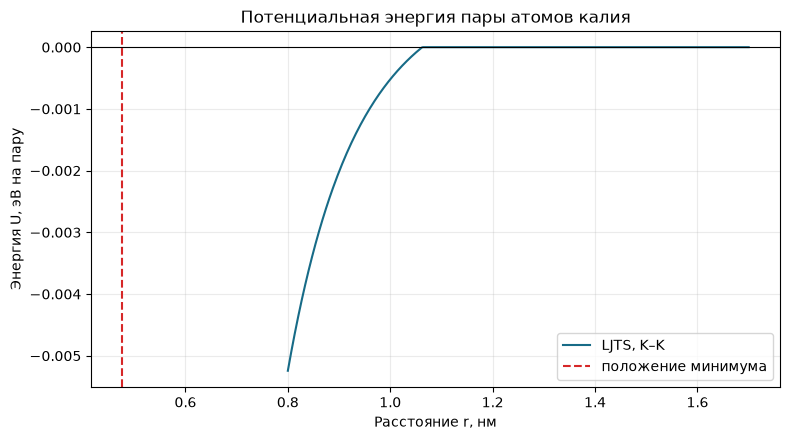

In [17]:
import matplotlib.pyplot as plt  # библиотека построения графиков

distance_nm = np.linspace(0.80, 1.70, 400)  # список расстояний в нанометрах
distance_m = distance_nm * 1e-9  # переводим нм в м: 1 нм = 10^-9 м
sigma = K_LJ.sigma  # обращаемся к атрибуту sigma объекта параметров
epsilon = K_LJ.epsilon  # энергия одной пары в джоулях
cutoff = 2.5 * sigma  # радиус обрезания потенциала в метрах
sr6 = (sigma / distance_m) ** 6  # шестая степень безразмерного отношения sigma/r
sr6_cut = (sigma / cutoff) ** 6  # такое же отношение на границе cutoff
u_lj = 4 * epsilon * (sr6**2 - sr6)  # энергия LJ для каждой точки массива
u_cut = 4 * epsilon * (sr6_cut**2 - sr6_cut)  # энергия в cutoff, вычитаем её для непрерывности
energy_ev = (u_lj - u_cut) / 1.602176634e-19  # Дж переводим в эВ на пару
energy_ev[distance_m >= cutoff] = 0.0  # за cutoff пары не взаимодействуют в LJTS

fig, ax = plt.subplots(figsize=(8, 4.5))  # создаём рисунок и область координат
ax.plot(distance_nm, energy_ev, color="#176b87", label="LJTS, K–K")
ax.axhline(0, color="black", linewidth=0.8)  # линия нулевой энергии
ax.axvline(K_LJ.r_min * 1e9, color="tab:red", linestyle="--", label="положение минимума")
ax.set(title="Потенциальная энергия пары атомов калия", xlabel="Расстояние r, нм", ylabel="Энергия U, эВ на пару")
ax.grid(alpha=0.25)  # лёгкая сетка помогает оценивать значения
ax.legend()  # отображаем пояснение к линиям
fig.tight_layout()  # подбираем поля рисунка
plt.show()  # выводим рисунок под ячейкой


#### Интерпретация примера

На коротких расстояниях энергия резко возрастает — это отражает сильное отталкивание при перекрытии электронных оболочек. Яма ниже нуля соответствует притяжению; её минимум равен $-\varepsilon$. На cutoff сдвинутая энергия плавно достигает нуля, после cutoff взаимодействие отключено. Для реальных атомов калия простая парная LJ-модель не является исчерпывающим описанием металлической связи; график демонстрирует математическую модель, принятую в учебном коде.

### 5. Как читать результаты остальных работ

У NVE-расчёта (постоянные число частиц, объём и полная энергия) кинетическая и потенциальная энергии обычно обмениваются, тогда как их сумма должна оставаться близкой к постоянной. Температура мгновенно флуктуирует, давление содержит кинетический и вириальный вклады. В ансамбле NVE температура не фиксируется термостатом. Чтобы назвать давление равновесным, одной красивой полки на графике недостаточно: нужно проверить отсутствие заметного тренда и оценить неопределённость с учётом корреляции временных наблюдений.

Каждая расчётная работа открывается отдельно и повторно задаёт свои импорты и параметры — её можно запускать самостоятельно. Во введении классы далее не требуются, но в ядре класс `MDEngine` объединяет конфигурацию, состояние частиц и операцию одного шага: объект создаётся как `engine = MDEngine(config)`, а метод `engine.step()` меняет состояние на следующий момент времени и возвращает словарь наблюдаемых величин.

### 6. Вопросы для защиты

1. **Чем отличаются Markdown- и Python-ячейки?** Markdown оформляет текст и формулы; Python исполняет вычисления.
2. **Зачем важен порядок ячеек?** Поздняя ячейка использует переменные, которые создали ранние.
3. **Что такое переменная?** Имя, которому присвоено значение для последующего использования.
4. **Что делает `import numpy as np`?** Подключает инструменты NumPy и позволяет обращаться к ним через короткое имя `np`.
5. **Чем список отличается от NumPy-массива?** Список — универсальная последовательность Python; массив ориентирован на численные операции над многими элементами.
6. **Почему нужен seed?** Он фиксирует псевдослучайную последовательность, чтобы повторить и сравнить расчёт.
7. **Что физически означает минимум LJ-потенциала?** Устойчивое расстояние пары, при котором суммарная сила равна нулю, а энергия минимальна.
8. **Зачем нужен маленький временной шаг?** Чтобы численно разрешить движение и изменение сил между соседними моментами времени.
9. **Почему 2D-результат нельзя без оговорок считать свойством объёмного калия?** В модели нет третьего измерения и электронных/многочастичных эффектов металла.
10. **Что делать после ошибки?** Прочитать тип ошибки и ячейку, проверить пропущенные предыдущие ячейки и при необходимости перезапустить ядро с выполнением сверху вниз.

## Лабораторная работа 1. Двумерный калий с периодическими границами

**Цель:** смоделировать движение одноатомного газа калия в двумерной коробке и проверить поведение энергии, температуры и давления в ансамбле NVE.

**Система:** 1035 атомов K, коробка $24\times24$ нм, заданная температура $900\,^{\circ}\mathrm C=1173.15$ K, периодические условия по x и y.

**Ожидаемый результат:** траектория и графики наблюдаемых величин; малая относительная ошибка полной энергии при разумном шаге интегрирования. Давление равновесия будет оцениваться отдельно в работе 02.

**Студент:** ____________________  **Группа:** __________  **Преподаватель:** ____________________

> Перед запуском выберите `DEMO` или `FULL` в первой конфигурационной ячейке. DEMO сохраняет полное число частиц, но сокращает траекторию; он не заменяет производственный расчёт. Notebook содержит весь необходимый код и запускается в Colab без клонирования репозитория.

### 1. Постановка задачи и проверка результата

Нужно получить микроскопическую траекторию атомов, вычисляя силы из парного потенциала и перемещая частицы по закону Ньютона. Периодические границы имитируют повторяющиеся ячейки вещества и не дают частицам искусственно ударяться о край коробки.

Корректность проверяем по четырём признакам: (1) координаты остаются в коробке после периодического заворачивания; (2) пары на противоположных гранях взаимодействуют по кратчайшему minimum-image расстоянию; (3) полная энергия NVE не имеет систематического дрейфа, превышающего численный допуск; (4) температура и давление флуктуируют как мгновенные величины, а не насильно удерживаются на одном значении. Периодическая картинка сама по себе не доказывает равновесие.

### 2. Теория и исходные данные

Сила на частицу $i$ равна $\mathbf F_i=-\nabla_i U$. Для пары используется LJTS из введения: LJ-потенциал с вычтенным значением в $r_c=2.5\sigma$ и нулём за cutoff. Сдвиг делает энергию непрерывной, но производная (и сила) в cutoff может быть разрывной. При $\mathbf r_{ij}=\mathbf r_i-\mathbf r_j$ модуль расстояния вычисляется с minimum image; сила пары на второй атом противоположна силе на первом.

Для каждой компоненты скорости Maxwell–Boltzmann даёт дисперсию $k_BT/m$. В плоскости $2N$ степеней свободы; если скорость центра масс удалена, $f=2N-2$ и $T=2K/(f k_B)$. В NVE интегратор Velocity Verlet использует координатное обновление второго порядка, пересчитывает силу в новой точке и затем обновляет скорость.

Двумерное вириальное давление: $P_{2D}=(K+W/2)/A$, где $K$ — полная кинетическая энергия (Дж), $W=\sum_{i<j}\mathbf r_{ij}\cdot\mathbf F_{ij}$ — вириал пар (Дж), $A=L_xL_y$ — площадь (м²). Поэтому $P_{2D}$ имеет единицы Дж/м² = Н/м, а не Па. Условное эквивалентное 3D-давление — $P_{2D}/z$, если заранее оговорить эффективную толщину слоя $z$.

| Величина | Обозначение | Значение | Единица | Пояснение |
|---|---:|---:|---|---|
| Число частиц | $N$ | 1035 | 1 | Получено из концентрации 4 моль/л по процедуре задания, см. расчёт ниже |
| Температура | $T$ | 900 °C = 1173.15 | K | $T_K=T_{°C}+273.15$ |
| Размер коробки | $L_x,L_y$ | 24, 24 | nm | Площадь $5.76\cdot10^{-16}$ м² |
| Масса атома K | $m$ | 6.4924$\cdot10^{-26}$ | kg | 39.0983 u, IUPAC/CIAAW |
| Размер LJ | $\sigma$ | 0.4250 | nm | Фиксированное значение модели проекта |
| Глубина ямы | $\varepsilon/k_B$ | 850 | K | $\varepsilon=850k_B$ Дж на частицу/пару в парном потенциале |
| Обрезание | $r_c$ | $2.5\sigma$ | nm | Энергетически сдвинутый LJTS |
| Временной шаг | $\Delta t$ | 1 | fs | $1\,\mathrm{fs}=10^{-15}$ s |

Параметры K–K заданы выше, в ячейке физических констант; в проекте отсутствует однозначная ссылка на источник именно пары $\sigma=0.4250$ нм, $\varepsilon/k_B=850$ K. Не следует выдавать её за точную универсальную параметризацию калия. Eslami, Mozaffari и Moghadasi (2010, DOI: [10.1007/bf03246015](https://doi.org/10.1007/bf03246015)) сравнивают LJ 12–6 с альтернативными потенциалами и обсуждают его ограничения для фазового поведения калия. Масса: [CIAAW atomic weights](https://ciaaw.org/atomic-weights.htm); точные $k_B$ и $N_A$: SI/BIPM.

**Как получено N.** При $C=4$ моль/л в 1 л имеется $N_{ref}=C V_{ref}N_A$ атомов. Толщина слоя выбрана как $z=(V_{ref}/N_{ref})^{1/3}$. В одном квадратном слое со стороной $V_{ref}^{1/3}=10$ см содержится $N_{layer}=N_{ref}z/V_{ref}^{1/3}$ частиц; перенос на площадь коробки даёт $N=N_{layer}A/(V_{ref}^{1/3})^2\approx1035.05$, округлённо 1035. Здесь объём и толщина задают лишь условный переход из 3D-концентрации к 2D-слою.

### 3. Подключение библиотек и выбор режима

Следующие Python-ячейки содержат полное MD-ядро непосредственно в notebook: физические параметры, силы, интегратор и функции анализа. Внешние `.py`-файлы и репозиторий не нужны. После них конфигурационная ячейка подключает NumPy и Matplotlib. `default_config()` возвращает настройки системы. Число шагов регулирует длину траектории, `sample_interval` — частоту сохранения физических величин, `frame_interval` — частоту кадров. `history` будет словарём массивов, а `frames` — массивом координат для анимации.

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display



MODE = 'DEMO'  # Для полного расчёта замените строку на 'FULL' и выполните notebook заново.
if MODE == 'DEMO':
    N_STEPS, SAMPLE_EVERY, FRAME_EVERY = 300, 1, 10
elif MODE == 'FULL':
    N_STEPS, SAMPLE_EVERY, FRAME_EVERY = 50_000, 10, 500
else:
    raise ValueError("MODE должен быть 'DEMO' или 'FULL'")
SEED = 7
config = default_config(seed=SEED, force_backend='cell_list', periodic_x=True, periodic_y=True)
print(f'Режим {MODE}: N={config.n_particles}, шагов={N_STEPS}, dt={config.dt / 1e-15:.1f} фс, длительность={N_STEPS * config.dt * 1e12:.3f} пс, seed={SEED}')


Режим DEMO: N=1035, шагов=300, dt=1.0 фс, длительность=0.300 пс, seed=7


### 4. Выполнение траектории

`run_nve(config, ...)` создаёт объект-движок `MDEngine`, подготавливает координаты и скорости, затем повторяет Velocity Verlet указанное число раз. Параметр `sample_interval` задаёт, через сколько шагов добавлять наблюдения в историю; `frame_interval` управляет сохранением координат для движения частиц. Возвращаются два объекта: `history` — словарь NumPy-массивов (`step`, `time`, энергии, температура, давление), `frames` — координаты частиц для выбранных моментов. Сначала выводим несколько элементов словаря и размер массива кадров: это пример просмотра результата функции и проверки, что расчёт действительно выполнен.

In [19]:
history, frames = run_nve(config, n_steps=N_STEPS, sample_interval=SAMPLE_EVERY, frame_interval=FRAME_EVERY)
print('Ключи и количество наблюдений:', {name: len(values) for name, values in history.items()})
print('Размер массива кадров (кадр, частица, координата):', frames.shape)
print(f"Начальная T={history['temperature'][0]:.2f} K; конечная T={history['temperature'][-1]:.2f} K")


Ключи и количество наблюдений: {'step': 301, 'kinetic_energy': 301, 'potential_energy': 301, 'total_energy': 301, 'temperature': 301, 'pressure_2d': 301, 'time': 301}
Размер массива кадров (кадр, частица, координата): (31, 1035, 2)
Начальная T=1173.15 K; конечная T=1306.79 K


### 5. Графики и диагностика сохранения энергии

Следующая ячейка строит три панели: обмен кинетической и потенциальной энергией вместе с полной энергией; отклонение полной энергии от начального значения; температуру и 2D-давление во времени. Срез `history['...']` обращается к массиву по строковому ключу словаря. Энергии показаны в $10^{-18}$ Дж, чтобы числа было удобно читать. `np.max` находит наибольшее абсолютное относительное отклонение энергии. Идеальное газовое значение давления — только ориентир, оно не подгоняется к MD-данным и не учитывает вириальную поправку.

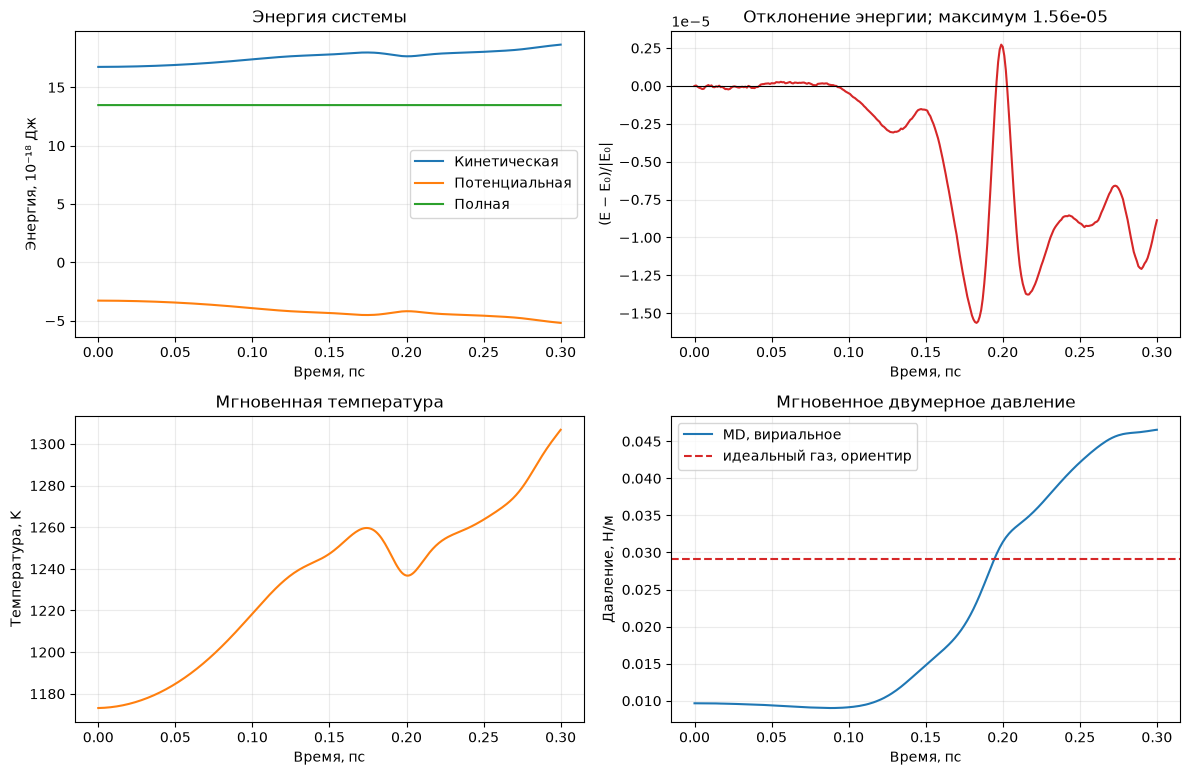

Максимальный относительный дрейф полной энергии: 1.5637e-05 (1.5637e-03 %)
Средняя T за сохранённую траекторию: 1233.044 K; это не автоматически равновесное значение
Среднее мгновенное P₂D за эту траекторию: 2.22257e-02 Н/м
Условный эквивалент 3D для среднего: 2.97938e+07 Па, при z=0.746 нм


In [20]:
time_ps = history['time'] * 1e12  # секунды переводим в пикосекунды
energy_scale = 1e18
initial_energy = history['total_energy'][0]
relative_drift = (history['total_energy'] - initial_energy) / abs(initial_energy)
ideal_pressure_2d = config.n_particles * BOLTZMANN * config.temperature / config.box.area
max_drift = float(np.max(np.abs(relative_drift)))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for key, label in [('kinetic_energy', 'Кинетическая'), ('potential_energy', 'Потенциальная'), ('total_energy', 'Полная')]:
    axes[0, 0].plot(time_ps, history[key] * energy_scale, label=label)
axes[0, 0].set(title='Энергия системы', xlabel='Время, пс', ylabel='Энергия, 10⁻¹⁸ Дж'); axes[0, 0].legend()
axes[0, 1].plot(time_ps, relative_drift, color='tab:red')
axes[0, 1].axhline(0, color='black', linewidth=0.8)
axes[0, 1].set(title=f'Отклонение энергии; максимум {max_drift:.2e}', xlabel='Время, пс', ylabel='(E − E₀)/|E₀|')
axes[1, 0].plot(time_ps, history['temperature'], color='tab:orange')
axes[1, 0].set(title='Мгновенная температура', xlabel='Время, пс', ylabel='Температура, K')
axes[1, 1].plot(time_ps, history['pressure_2d'], label='MD, вириальное')
axes[1, 1].axhline(ideal_pressure_2d, color='tab:red', linestyle='--', label='идеальный газ, ориентир')
axes[1, 1].set(title='Мгновенное двумерное давление', xlabel='Время, пс', ylabel='Давление, Н/м'); axes[1, 1].legend()
for axis in axes.flat: axis.grid(alpha=0.25)
fig.tight_layout(); plt.show()

print(f'Максимальный относительный дрейф полной энергии: {max_drift:.4e} ({100 * max_drift:.4e} %)')
print(f'Средняя T за сохранённую траекторию: {np.mean(history["temperature"]):.3f} K; это не автоматически равновесное значение')
print(f'Среднее мгновенное P₂D за эту траекторию: {np.mean(history["pressure_2d"]):.5e} Н/м')
print(f'Условный эквивалент 3D для среднего: {np.mean(history["pressure_2d"]) / LAYER_THICKNESS:.5e} Па, при z={LAYER_THICKNESS * 1e9:.3f} нм')


#### Физическая интерпретация

В NVE температура не закреплена термостатом: система перераспределяет энергию между движением и взаимодействиями, поэтому кинетическая энергия, потенциальная энергия, температура и давление флуктуируют. Их средние могут сместиться после старта, если начальное размещение не было равновесной конфигурацией. Важная проверка интегратора — полная энергия $E=K+U$: для малых шагов Verlet обычно даёт ограниченные колебания около начального значения. Небольшой обратимый/осциллирующий дрейф не равен статистическому шуму; крупный монотонный дрейф указывал бы на слишком большой шаг или численную проблему.

Идеально-газовый ориентир $Nk_BT/A$ может отличаться от MD из-за взаимодействий и различия условий. Среднее в этой ячейке вычислено по всей сохранённой траектории, включая возможный переходный участок; его нельзя называть равновесным давлением без отдельной диагностики. Короткий DEMO показывает работу вычислительного процесса, но не позволяет заключать о равновесии.

### 6. Расположение частиц и сохранение результатов

Здесь строятся начальная и конечная конфигурации из `frames`. В NumPy-индексации `frames[0, :, 0]` означает x-координаты всех частиц первого кадра. `save_task1_animation` сохраняет GIF и не меняет траекторию. Функция `np.savetxt` экспортирует числовые столбцы CSV, а `Path` задаёт переносимый путь внутри текущей среды Colab.

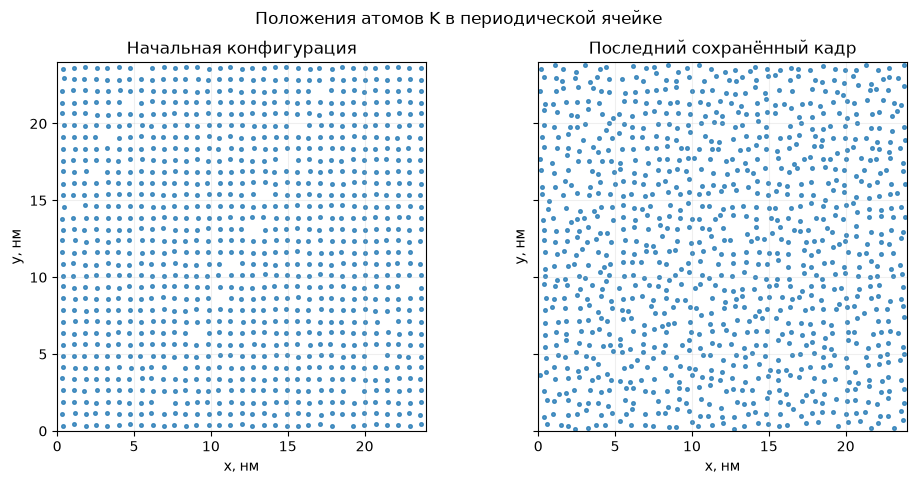

CSV и GIF сохранены в: output/notebooks/task1_periodic


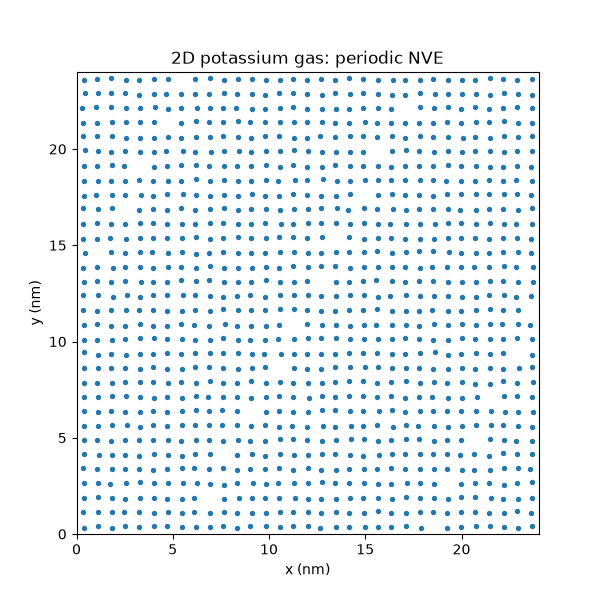

**Расчётная сводка (DEMO, seed 7):** N=1035; длительность 0.300 пс; начальная T=1173.15 K; средняя T по ряду=1233.04 K; среднее P₂D=2.22257e-02 Н/м; условный 3D-эквивалент=2.97938e+07 Па; максимальный относительный дрейф E=1.564e-05. Средние давления и температуры относятся ко всей конечной траектории и не означают автоматически равновесие.

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), sharex=True, sharey=True)
for axis, frame, title in zip(axes, [frames[0], frames[-1]], ['Начальная конфигурация', 'Последний сохранённый кадр']):
    axis.scatter(frame[:, 0] * 1e9, frame[:, 1] * 1e9, s=7, alpha=0.75)
    axis.set(title=title, xlabel='x, нм', ylabel='y, нм', xlim=(0, config.box.lx * 1e9), ylim=(0, config.box.ly * 1e9), aspect='equal')
    axis.grid(alpha=0.2)
fig.suptitle('Положения атомов K в периодической ячейке'); fig.tight_layout(); plt.show()

output_dir = PROJECT_ROOT / 'output' / 'notebooks' / 'task1_periodic'
output_dir.mkdir(parents=True, exist_ok=True)
columns = np.column_stack([history[key] for key in history])
np.savetxt(output_dir / 'timeseries.csv', columns, delimiter=',', header=','.join(history), comments='')
save_task1_animation(frames, config.box.lx, output_dir / 'trajectory.gif')
print(f'CSV и GIF сохранены в: {output_dir.relative_to(PROJECT_ROOT)}')
display(Image(filename=str(output_dir / 'trajectory.gif')))
display(Markdown(f'**Расчётная сводка ({MODE}, seed {SEED}):** N={config.n_particles}; длительность {N_STEPS * config.dt * 1e12:.3f} пс; начальная T={history["temperature"][0]:.2f} K; средняя T по ряду={np.mean(history["temperature"]):.2f} K; среднее P₂D={np.mean(history["pressure_2d"]):.5e} Н/м; условный 3D-эквивалент={np.mean(history["pressure_2d"]) / LAYER_THICKNESS:.5e} Па; максимальный относительный дрейф E={max_drift:.3e}. Средние давления и температуры относятся ко всей конечной траектории и не означают автоматически равновесие.'))


### 7. Вывод по расчёту

Рассчитанная численная сводка выведена непосредственно над этим разделом из выполненной траектории. Укажите в отчёте режим, длительность и seed. DEMO проверяет только работу расчётной цепочки; FULL даёт более длинный ряд, но само по себе увеличение длины не заменяет отдельную проверку стационарности, выполненную в работе 02. В NVE полная энергия должна сохраняться с численной точностью, а мгновенные T и P могут флуктуировать.

### Возможные вопросы преподавателя

1. **Почему применён LJ-потенциал?** Это прозрачная парная модель короткодействующего отталкивания и дисперсионного притяжения; для металла это упрощение, а не полный электронный потенциал.
2. **Что означает $\sigma$?** Расстояние, где несдвинутый LJ-потенциал равен нулю; минимум находится при $2^{1/6}\sigma$.
3. **Зачем cutoff?** Ограничить радиус взаимодействия и ускорить расчёт; сдвиг энергии приводит её к нулю на cutoff.
4. **Как работает minimum image?** Для каждой периодической оси выбирается ближайший образ частицы, чтобы учесть взаимодействие через границу.
5. **Что делает `run_nve`?** Инициализирует движок, многократно применяет шаг Velocity Verlet и возвращает словарь временных наблюдений и координаты кадров.
6. **Зачем в `run_nve` передавать `sample_interval` и `frame_interval`?** Они определяют частоту сохранения графиковых величин и координат кадров, а не физический шаг интегратора.
7. **Почему давление в 2D — Н/м?** В двумерном вириальном выражении энергия делится на площадь: Дж/м² = Н/м.
8. **Почему температура может отличаться от заданной?** Задано начальное распределение скоростей; в NVE термостат не поддерживает температуру, а энергия обменивается между кинетической и потенциальной формами.
9. **Как проверить сохранение энергии?** Построить $(E(t)-E_0)/|E_0|$ и проверить малые ограниченные отклонения при уменьшении шага и сравнении траекторий.
10. **Является ли среднее DEMO равновесным давлением?** Нет. Короткий запуск предназначен для технической проверки; нужно отдельно обнаружить переходный участок и проверить корреляции.

## Лабораторная работа 2. Диагностика установления равновесия

**Цель:** определить, есть ли в рассчитанной периодической траектории стационарный участок, и оценить среднее двумерное давление с неопределённостью.

**Система:** та же модель 1035 атомов K, NVE, $24\times24$ нм, PBC по обеим осям.

**Ожидаемый результат:** графики температуры и давления с явной отметкой найденного переходного участка либо честный вывод, что заданный критерий не сработал.

**Студент:** ____________________  **Группа:** __________  **Преподаватель:** ____________________

> DEMO предназначен для демонстрации критерия и может не содержать достаточно длинного стационарного участка. FULL повторяет траекторию задания (30 000 шагов, 1 фс, seed 7). Отсутствие срабатывания не следует заменять выбранной вручную точкой.

### 1. Постановка задачи и физический смысл равновесия

Термодинамическое равновесие означает отсутствие макроскопически наблюдаемого направленного изменения состояния при фиксированных условиях; при этом микроскопическое движение и мгновенные значения давления и температуры продолжают флуктуировать. Сразу после запуска координаты расставлены по решётке, а не выбраны из равновесного распределения. Поэтому начальный участок может содержать релаксацию структуры и перераспределение между потенциальной и кинетической энергией.

В коде реализован конкретный эвристический критерий: сравниваются средние температуры и давления в двух соседних группах временных блоков; для давления изменение нормируется на идеальное 2D-давление. Критерий требует несколько последовательных успешных сравнений. Это диагностическое правило задания, а не строгий тест стационарности и не доказательство полного термодинамического равновесия. Если он не сработал, результат так и фиксируется.

Для выбранного участка рассчитываются среднее давление $\bar P$, выборочное стандартное отклонение $s=\sqrt{\sum(P_i-\bar P)^2/(n-1)}$ и стандартная ошибка среднего (SEM). При наличии как минимум двух целых блоков модуль оценивает SEM как $s_{block}/\sqrt{n_{block}}$, где $s_{block}$ — стандартное отклонение средних по блокам; это лучше учитывает кратковременную автокорреляцию, чем формула $s/\sqrt n$. Если данных мало для двух блоков, используется упрощённая оценка, которая может занижать ошибку при корреляции. Увеличение числа сохранённых кадров не эквивалентно такому же увеличению независимой статистики.

Давление здесь — двумерное вириальное $P_{2D}=(K+W/2)/A$ в Н/м. Математическая модель, параметры и ограничения K–K описаны в работах 00–01; в этой работе основной новый вопрос — статистическая стационарность, а не повторное объяснение потенциала.

#### Исходные параметры расчёта

| Параметр | Значение FULL | Единица | Пояснение |
|---|---:|---|---|
| Число атомов | 1035 | 1 | Вариант K, 4 моль/л |
| Температура и начальное условие | 1173.15 | K | 900 °C + 273.15; в NVE не закрепляется термостатом |
| Коробка / площадь | 24 × 24 / 576 | нм / нм² | PBC по x и y |
| Масса K | 6.4924·10⁻²⁶ | кг | 39.0983 u |
| $\sigma$, $\varepsilon/k_B$ | 0.4250; 850 | нм; K | Зафиксированные параметры учебной модели |
| $\Delta t$, длительность | 1; 30 000 | фс; шагов | FULL = 30 пс, sample interval = 1 |
| Seed | 7 | — | Повторяемая начальная конфигурация |
| Блок критерия | 2000 наблюдений | — | 5 блоков сравнения, 3 последовательных сравнения; допуски T 2%, P 5% идеального масштаба |

В DEMO число частиц и физические параметры не меняются, сокращаются только траектория и размер блоков; значения DEMO напечатаны в конфигурационной ячейке.

### 2. Режим, seed и конфигурация

`default_config` создаёт неизменяемую конфигурацию с числом частиц, температурой, SI-массой, коробкой, шагом времени, cutoff и настройками периодичности. Значение `seed=7` фиксирует случайную инициализацию. `run_nve` возвращает временные ряды; здесь кадры координат не нужны, поэтому `frame_interval` выбран больше длины расчёта. В FULL используется блок в 2000 сохранённых наблюдений и настройка критерия из скрипта задания: пять блоков для каждого среднего и три последовательных сравнения. В DEMO параметры блоков явно сокращены, чтобы проиллюстрировать логику на коротком ряду; такой критерий DEMO не является выводом о физическом равновесии.

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display


MODE = 'DEMO'  # поменяйте на FULL для исходной длительной траектории
if MODE == 'DEMO':
    N_STEPS, BLOCK_SIZE, COMPARISON_BLOCKS, CONSECUTIVE = 400, 10, 2, 2
elif MODE == 'FULL':
    N_STEPS, BLOCK_SIZE, COMPARISON_BLOCKS, CONSECUTIVE = 30_000, 2_000, 5, 3
else: raise ValueError("MODE должен быть DEMO или FULL")
SEED = 7
config = default_config(seed=SEED, force_backend='cell_list', periodic_x=True, periodic_y=True)
print(f'{MODE}: N={config.n_particles}; шаги={N_STEPS}; блок={BLOCK_SIZE} наблюдений; comparisons={COMPARISON_BLOCKS}; подряд={CONSECUTIVE}; seed={SEED}')


DEMO: N=1035; шаги=400; блок=10 наблюдений; comparisons=2; подряд=2; seed=7


### 3. Считаем траекторию и ищем переходный участок

После запуска `run_nve` переменные температуры и давления находятся в словаре `history`. `.astype(int)` превращает сохранённые номера шагов в целые числа, которые ожидает функция поиска. Идеальное давление вычисляется как $Nk_BT/A$ только для нормировки критерия и контрольного масштаба. Вызов `find_equilibration_index` возвращает индекс наблюдения, с которого по эвристике начинается производственный участок. Если длины ряда недостаточно или критерий не выполнен, функция сообщает `ValueError`; ниже ошибка перехватывается и записывается как отсутствие найденной точки, а не скрывается.

In [23]:
history, _ = run_nve(config, n_steps=N_STEPS, sample_interval=1, frame_interval=N_STEPS + 1)
ideal_pressure = config.n_particles * BOLTZMANN * config.temperature / config.box.area
try:
    equilibrium_index = find_equilibration_index(
        history['step'].astype(int), history['temperature'], history['pressure_2d'], ideal_pressure,
        block_size=BLOCK_SIZE, comparison_blocks=COMPARISON_BLOCKS, consecutive=CONSECUTIVE,
    )
    criterion_met = True
    print(f'Критерий выполнен: начало участка — индекс {equilibrium_index}, шаг {int(history["step"][equilibrium_index])}, время {history["time"][equilibrium_index] * 1e12:.3f} пс')
except ValueError as error:
    equilibrium_index = None
    criterion_met = False
    print(f'Критерий НЕ выполнен: {error}')
    print('Не называйте траекторию равновесной. Увеличьте длительность и исследуйте диагностические графики.')


Критерий выполнен: начало участка — индекс 30, шаг 30, время 0.030 пс


### 4. Температура, давление и область статистики

Красная вертикальная линия и зелёная заливка появятся только если функция вернула индекс. Они показывают начало участка по заданному критерию, а не момент резкого изменения физического состояния. Если критерия нет, изображается вся траектория без придуманного разделителя. Среднее и разброс после порога считаются по `block_statistics`; функция возвращает объект с полями `mean`, `std`, `sem` и `n_samples`. `std` показывает разброс мгновенных значений, `sem` — оценку ошибки среднего с блочной поправкой, если осталось достаточно блоков.

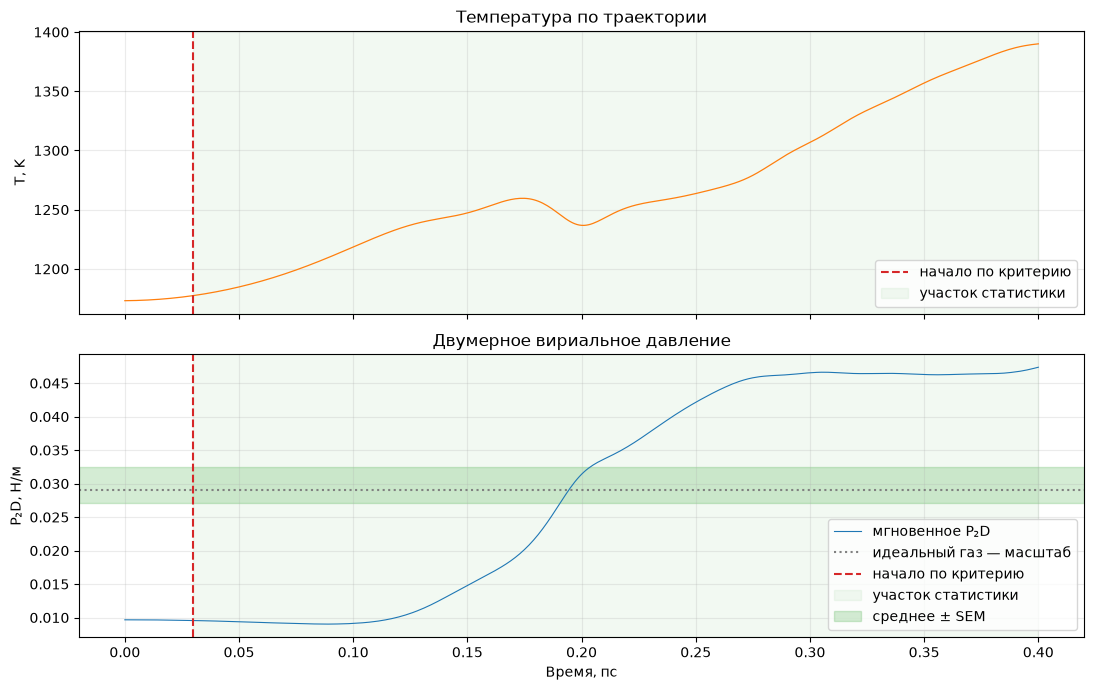

P̄ = 2.97845e-02 Н/м; стандартное отклонение s = 1.60244e-02 Н/м; SEM = 2.66518e-03 Н/м
Постпереходных наблюдений: 371; блоков для оценки SEM: 37


In [24]:
if criterion_met:
    stats = block_statistics(history['pressure_2d'], equilibrium_index, block_size=BLOCK_SIZE)
    pressure_mean = stats.mean
else:
    stats = None  # без обоснованного участка не рассчитываем P_eq
    pressure_mean = None

time_ps = history['time'] * 1e12
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(time_ps, history['temperature'], color='tab:orange', linewidth=0.9)
axes[0].set(title='Температура по траектории', ylabel='T, K')
axes[1].plot(time_ps, history['pressure_2d'], color='tab:blue', linewidth=0.8, label='мгновенное P₂D')
axes[1].axhline(ideal_pressure, color='gray', linestyle=':', label='идеальный газ — масштаб')
if criterion_met:
    start_time = time_ps[equilibrium_index]
    for axis in axes: axis.axvline(start_time, color='tab:red', linestyle='--', label='начало по критерию')
    for axis in axes: axis.axvspan(start_time, time_ps[-1], color='tab:green', alpha=0.06, label='участок статистики')
    axes[1].axhspan(stats.mean - stats.sem, stats.mean + stats.sem, color='tab:green', alpha=0.2, label='среднее ± SEM')
axes[1].set(title='Двумерное вириальное давление', xlabel='Время, пс', ylabel='P₂D, Н/м')
for axis in axes: axis.grid(alpha=0.25); axis.legend()
fig.tight_layout(); plt.show()

if criterion_met:
    print(f'P̄ = {stats.mean:.5e} Н/м; стандартное отклонение s = {stats.std:.5e} Н/м; SEM = {stats.sem:.5e} Н/м')
    print(f'Постпереходных наблюдений: {stats.n_samples}; блоков для оценки SEM: {stats.n_samples // BLOCK_SIZE}')
else:
    print('Среднее давление всей траектории:', f'{np.mean(history["pressure_2d"]):.5e} Н/м')
    print('Это только описательная средняя по конечной траектории, НЕ оценка равновесного давления.')


#### Интерпретация и ограничения статистики

Признаком подхода к стационарному режиму служит отсутствие устойчивого тренда средних температуры и давления на последовательных окнах, а не отсутствие мгновенных колебаний. В этой реализации окна сравнивают средние и tolerances (2% для температуры и 5% масштаба идеального давления) на входе функции. Поскольку давление и температура могут быть автокоррелированы, соседние точки траектории не независимы. Блочная SEM уменьшает риск искусственно считать каждую точку независимой, но выбор размера блока тоже следует проверить: повторить анализ с более крупными блоками, проверить график и увеличить продолжительность расчёта.

Критерий может дать ложное срабатывание на коротком случайном плато или не сработать при стационарном ряду из-за строгих допусков. Поэтому научно корректная проверка включает несколько независимых seed, увеличение длины траектории, сравнение средних разных окон и устойчивость результата к размеру блока. Если критерий не выполнен, следует сообщить, сколько шагов рассчитано, показать весь ряд и продолжить расчёт; объявлять равновесие вручную нельзя.

### 5. Экспорт и вывод

`np.savetxt` сохраняет только фактически рассчитанные временные значения. Импортированные `Path` формирует переносимый путь, `mkdir(parents=True, exist_ok=True)` создаёт каталог, если его ещё нет. Сводка ниже строится программно и разделяет случай «критерий выполнен» от случая «не выполнен».

In [25]:
output_dir = PROJECT_ROOT / 'output' / 'notebooks' / 'task2_equilibrium'
output_dir.mkdir(parents=True, exist_ok=True)
np.savetxt(output_dir / 'pressure_timeseries.csv', np.column_stack((history['step'], history['time'], history['temperature'], history['pressure_2d'])), delimiter=',', header='step,time_s,temperature_K,pressure_2d_N_per_m', comments='')
if criterion_met:
    start_step = int(history['step'][equilibrium_index])
    conclusion = f'Критерий выполнен на шаге {start_step}; давление {stats.mean:.5e} Н/м, s={stats.std:.3e} Н/м, SEM={stats.sem:.3e} Н/м по {stats.n_samples} наблюдениям. Это эвристическая оценка.'
else:
    mean_pressure = np.mean(history['pressure_2d'])
    conclusion = f'На {N_STEPS} шагах критерий не выполнен. Описательное среднее ряда {mean_pressure:.5e} Н/м; равновесное давление не заявляется.'
display(Markdown(f'**Вывод ({MODE}, seed {SEED}):** {conclusion}'))
print(f'Ряд давления сохранён: {output_dir.relative_to(PROJECT_ROOT) / "pressure_timeseries.csv"}')


**Вывод (DEMO, seed 7):** Критерий выполнен на шаге 30; давление 2.97845e-02 Н/м, s=1.602e-02 Н/м, SEM=2.665e-03 Н/м по 371 наблюдениям. Это эвристическая оценка.

Ряд давления сохранён: output/notebooks/task2_equilibrium/pressure_timeseries.csv


### Возможные вопросы преподавателя

1. **Что понимается под равновесием?** Макроскопические средние не имеют заметного временного тренда при неизменных условиях; микроскопические флуктуации остаются.
2. **Почему начальное состояние может быть неравновесным?** Решёточные координаты — удобная неперекрывающаяся инициализация, но не случайная выборка равновесного распределения.
3. **Что делает `find_equilibration_index`?** Сравнивает средние температуры и давления в последовательных блоках и возвращает первый индекс, удовлетворяющий заданному набору допусков.
4. **Почему это не строгое доказательство равновесия?** Любой конечный критерий ограничен выбранными окнами, допусками и конкретным шумным seed; он может ошибиться.
5. **Зачем блокировать временной ряд?** Блочные средние частично учитывают автокорреляцию и дают более реалистичную оценку неопределённости среднего.
6. **Чем стандартное отклонение отличается от SEM?** Отклонение характеризует разброс наблюдений; SEM — неопределённость оценки среднего.
7. **Почему последовательные кадры коррелированы?** Положение и скорость меняются непрерывно, поэтому состояние на соседних шагах близко.
8. **Что делать, если критерий не выполнен?** Не объявлять равновесие; показать всю траекторию, продлить расчёт, исследовать другие seed и проверить устойчивость к размеру блока.
9. **В каких единицах давление?** Н/м для 2D вириального pressure; Па получаются только после деления на условную толщину.
10. **Почему среднее полного ряда не обязательно $P_{eq}$?** В него может входить неравновесный переходный участок.

## Лабораторная работа 3. Калий между фиксированными углеродными стенками

**Цель:** изучить влияние четырёх непроницаемых в рамках модели стенок из неподвижных атомов углерода на траектории атомов калия и механическое давление на границы.

**Система:** 1035 частиц K в коробке $24\times24$ нм; все четыре границы представлены атомными рядами C; газ и стенки взаимодействуют потенциалом LJTS.

**Ожидаемый результат:** график движения K относительно C-стенок и временные зависимости энергий, температуры и силы на стенки на единицу длины.

**Студент:** ____________________  **Группа:** __________  **Преподаватель:** ____________________

> В DEMO сохраняется число частиц, но используется короткая траектория. FULL соответствует демонстрационным параметрам эксперимента task3 (2000 шагов). Измените `MODE` в первой ячейке, чтобы выбрать режим.

### 1. Постановка и теория стенок

Вместо периодического повторения области здесь задаются четыре ряда атомов углерода, закреплённых в пространстве. Частицы K взаимодействуют как друг с другом (K–K), так и с C-атомами (K–C); за пределами стенки дополнительных периодических копий нет. Если K приближается к стенке, отталкивающая часть потенциала разворачивает траекторию; более слабый притягивающий вклад может удерживать частицы рядом с поверхностью.

Геометрия — одномерный ряд атомов на каждой стороне 2D-прямоугольника. Расстояние вдоль алмазной поверхности принято равным $a/\sqrt2$, где параметр решётки алмаза $a=0.3567$ нм. Углы представлены один раз, чтобы не удваивать угловые атомы. Это двумерное сечение поверхности, не объёмный алмазный кристалл.

Для K–C применены правила Lorentz–Berthelot: $\sigma_{KC}=(\sigma_K+\sigma_C)/2$, $\varepsilon_{KC}=\sqrt{\varepsilon_K\varepsilon_C}$. UFF для атома углерода типа C_3 задаёт минимум $x_C=3.851$ Å и глубину $D_C=0.105$ ккал/моль. В стандартном LJ параметр $\sigma$ задаёт нулевое пересечение, поэтому $\sigma_C=x_C/2^{1/6}$. Энергию на моль переводим в энергию на пару/частицу множителем $4184/N_A$ Дж на ккал/моль.

Реакция фиксированных стенок позволяет вычислить механическое давление: модуль суммарной компоненты силы газа на стенку, делённый на длину этой стороны. Для левой/правой стенок $P_x=|\sum F_x|/L_y$, для верхней/нижней $P_y=|\sum F_y|/L_x$, единица Н/м. Это прямее характеризует контакт со стенкой, чем периодическая формула bulk-вириала. Энергия стенка–стенка не включается: координаты стенок постоянны, поэтому её изменение на динамику газа не влияет.

| Величина | Значение | Единица | Основание |
|---|---:|---|---|
| Частицы K | 1035 | атомов | Вариант 7 задания, из 4 моль/л |
| Температура | 1173.15 | K | 900 °C + 273.15 |
| Коробка | 24 × 24 | нм | Вариант 7 |
| $\sigma_K$, $\varepsilon_K/k_B$ | 0.4250; 850 | нм; K | Зафиксированные параметры кода, точный источник пары не найден |
| $x_C$, $D_C$ UFF | 3.851; 0.105 | Å; kcal/mol | Rappé et al., UFF, JACS 114 (1992), DOI [10.1021/ja00051a040](https://doi.org/10.1021/ja00051a040) |
| $a$, межрядное расстояние | 0.3567; 0.2522 | нм | Алмазная решётка; справочно [Argonne lattice constants](https://7id.xray.aps.anl.gov/calculators/crystal_lattice_parameters.html) |
| $\Delta t$, cutoff | 1 фс; $2.5\sigma$ | с; нм | Настройка модели |

Подвижные стенки, упругие моды, химическая связь и электронная проводимость не моделируются. Поэтому это исследование взаимодействия с эффективной фиксированной поверхностью, а не полноценная модель твёрдого тела.

### 2. Настройка кода

`MDEngine` — класс, который собирает конфигурацию, частицы, потенциалы и силы в одном объекте. `engine = MDEngine(config)` создаёт объект-состояние; `engine.step()` вызывает один шаг Velocity Verlet и возвращает словарь стандартных наблюдений. Силы реакции на каждую фиксированную стенку доступны в `engine.state.wall_reaction`; координаты атомов C лежат в `engine.wall_positions`. Здесь нужен собственный небольшой цикл, чтобы явно показать расчёт механического давления по каждой стороне: функция `run_nve` не возвращает раздельные силы стенок.

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

MODE = 'DEMO'  # Для полной траектории замените значение на 'FULL'.
if MODE == 'DEMO': N_STEPS, SAMPLE_EVERY, FRAME_EVERY = 300, 1, 10
elif MODE == 'FULL': N_STEPS, SAMPLE_EVERY, FRAME_EVERY = 2_000, 1, 20
else: raise ValueError("MODE должен быть DEMO или FULL")
SEED = 7
config = default_config(seed=SEED, force_backend='cell_list', periodic_x=False, periodic_y=False, wall_mode='all')
engine = MDEngine(config)
wall_positions = engine.wall_positions
print(f'{MODE}: N(K)={config.n_particles}, N(C)={len(wall_positions)}, steps={N_STEPS}, dt={config.dt / 1e-15:.1f} фс, seed={SEED}')


DEMO: N(K)=1035, N(C)=380, steps=300, dt=1.0 фс, seed=7


### 3. Сохраняем наблюдения и давление стенок

Функция ниже принимает номер шага и стандартный словарь наблюдений, читает вектор реакции стенок и делит силы на длины соответствующих сторон. Маски `left`, `right`, `bottom`, `top` выбирают углеродные атомы, лежащие на нужной координате границы; `np.isclose` учитывает погрешность представления чисел с плавающей точкой. При наличии углового атома его x- и y-компоненты относятся к двум перпендикулярным сторонам независимо. В список добавляются только реальные значения системы. Затем цикл `for` вызывает `engine.step()` столько раз, сколько задано `N_STEPS`, и копирует координаты через заданные интервалы кадров. `frames` сохраняются отдельно от временных рядов, чтобы не хранить все координаты каждого шага.

In [27]:
tolerance = max(1e-15, max(config.box.lx, config.box.ly) * 1e-12)
left = np.isclose(wall_positions[:, 0], 0.0, atol=tolerance)
right = np.isclose(wall_positions[:, 0], config.box.lx, atol=tolerance)
bottom = np.isclose(wall_positions[:, 1], 0.0, atol=tolerance)
top = np.isclose(wall_positions[:, 1], config.box.ly, atol=tolerance)
records, frames = [], [engine.state.positions.copy()]

def save_observation(step, observation):
    reaction = engine.state.wall_reaction  # сила, действующая газом на каждый фиксированный атом C
    p_left = abs(float(np.sum(reaction[left, 0]))) / config.box.ly
    p_right = abs(float(np.sum(reaction[right, 0]))) / config.box.ly
    p_bottom = abs(float(np.sum(reaction[bottom, 1]))) / config.box.lx
    p_top = abs(float(np.sum(reaction[top, 1]))) / config.box.lx
    record = dict(observation)
    record.update(step=float(step), time=step * config.dt, pressure_wall_x=0.5 * (p_left + p_right),
                  pressure_wall_y=0.5 * (p_bottom + p_top), pressure_wall_mean=0.25 * (p_left + p_right + p_bottom + p_top))
    records.append(record)

initial_kinetic = kinetic_energy(engine.state.velocities, config.mass)
initial_observation = {'kinetic_energy': initial_kinetic, 'potential_energy': engine.state.potential_energy,
                      'total_energy': initial_kinetic + engine.state.potential_energy,
                      'temperature': instantaneous_temperature(engine.state.velocities, config.mass, config.remove_com),
                      'pressure_2d': pressure_2d(initial_kinetic, engine.state.virial, config.box.area)}
save_observation(0, initial_observation)
for step in range(1, N_STEPS + 1):  # каждый проход — следующий шаг физического времени
    observation = engine.step()
    if step % SAMPLE_EVERY == 0: save_observation(step, observation)
    if step % FRAME_EVERY == 0: frames.append(engine.state.positions.copy())
history = {key: np.asarray([row[key] for row in records], dtype=float) for key in records[0]}
frames = np.asarray(frames)
print(f'Сохранено {len(records)} наблюдений и {len(frames)} кадров; shape кадров={frames.shape}')


Сохранено 301 наблюдений и 31 кадров; shape кадров=(31, 1035, 2)


### 4. Графики: энергия, температура, давление и конфигурация

Строим временные ряды и сравниваем начальный и последний сохранённые кадры. На графике давления отдельно показаны механические реакции на стенки и дополнительная вириальная оценка. Для фиксированных границ механическая сила стенки наиболее прямой observable; вириальное выражение полезно как дополнительная диагностика, но не следует без оговорок трактовать его как однородное bulk-давление. Анимация создаётся готовой функцией визуализации и сохраняется в GIF.

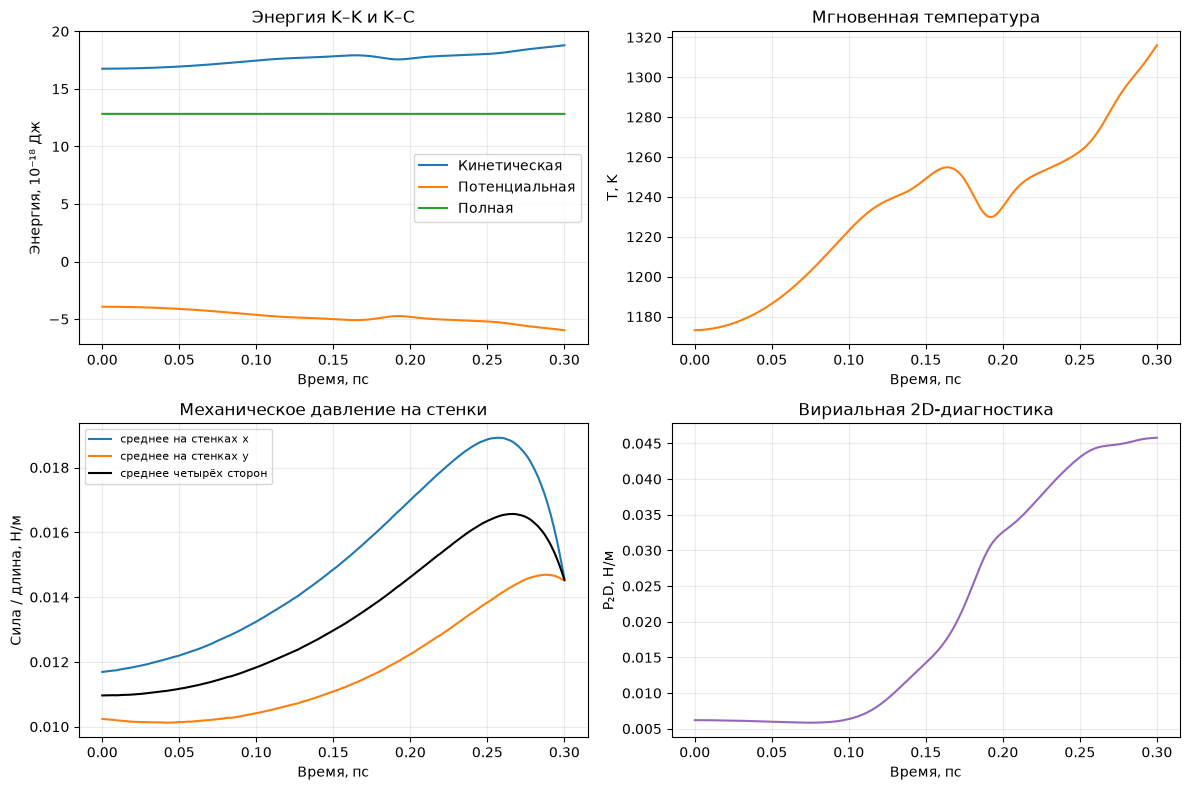

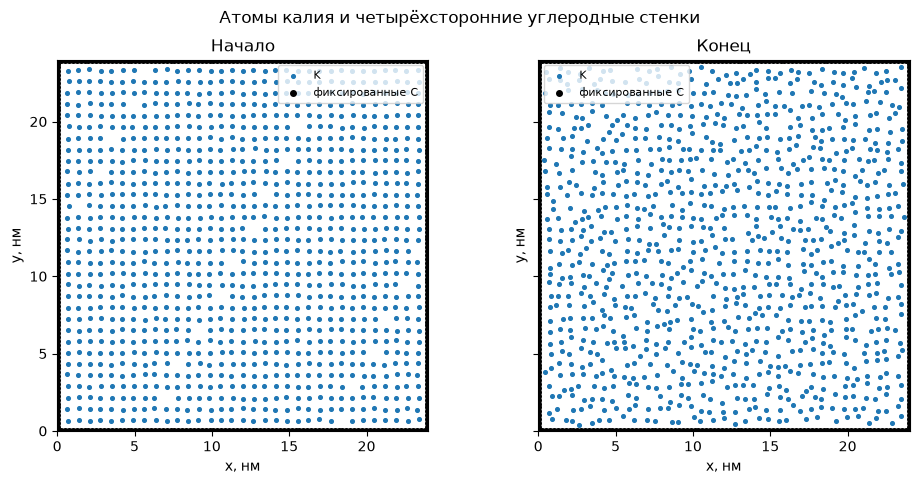

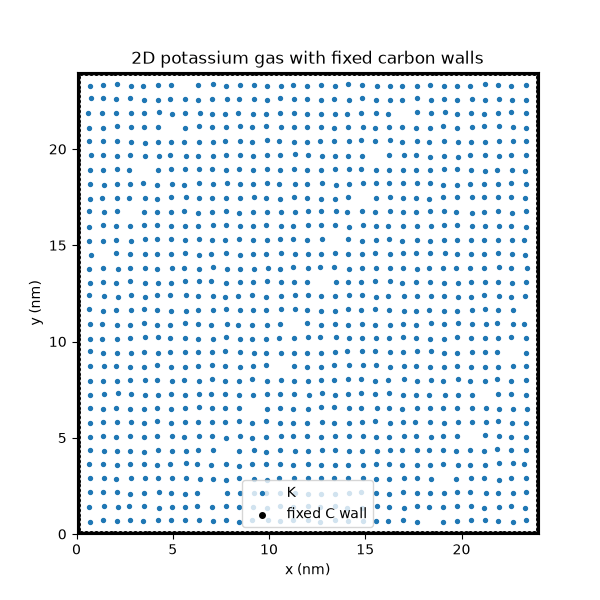

Данные и GIF сохранены в output/notebooks/task3_walls


In [28]:
time_ps = history['time'] * 1e12
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for key, label in [('kinetic_energy', 'Кинетическая'), ('potential_energy', 'Потенциальная'), ('total_energy', 'Полная')]:
    axes[0, 0].plot(time_ps, history[key] * 1e18, label=label)
axes[0, 0].set(title='Энергия K–K и K–C', xlabel='Время, пс', ylabel='Энергия, 10⁻¹⁸ Дж'); axes[0, 0].legend()
axes[0, 1].plot(time_ps, history['temperature'], color='tab:orange')
axes[0, 1].set(title='Мгновенная температура', xlabel='Время, пс', ylabel='T, K')
axes[1, 0].plot(time_ps, history['pressure_wall_x'], label='среднее на стенках x')
axes[1, 0].plot(time_ps, history['pressure_wall_y'], label='среднее на стенках y')
axes[1, 0].plot(time_ps, history['pressure_wall_mean'], color='black', linewidth=1.5, label='среднее четырёх сторон')
axes[1, 0].set(title='Механическое давление на стенки', xlabel='Время, пс', ylabel='Сила / длина, Н/м'); axes[1, 0].legend(fontsize=8)
axes[1, 1].plot(time_ps, history['pressure_2d'], color='tab:purple')
axes[1, 1].set(title='Вириальная 2D-диагностика', xlabel='Время, пс', ylabel='P₂D, Н/м')
for axis in axes.flat: axis.grid(alpha=0.25)
fig.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), sharex=True, sharey=True)
for axis, frame, title in zip(axes, [frames[0], frames[-1]], ['Начало', 'Конец']):
    axis.scatter(frame[:, 0] * 1e9, frame[:, 1] * 1e9, s=7, label='K')
    axis.scatter(wall_positions[:, 0] * 1e9, wall_positions[:, 1] * 1e9, s=16, color='black', label='фиксированные C')
    axis.set(title=title, xlabel='x, нм', ylabel='y, нм', xlim=(0, config.box.lx * 1e9), ylim=(0, config.box.ly * 1e9), aspect='equal'); axis.legend(fontsize=8)
fig.suptitle('Атомы калия и четырёхсторонние углеродные стенки'); fig.tight_layout(); plt.show()

output_dir = PROJECT_ROOT / 'output' / 'notebooks' / 'task3_walls'
output_dir.mkdir(parents=True, exist_ok=True)
np.savetxt(output_dir / 'timeseries.csv', np.column_stack([history[key] for key in history]), delimiter=',', header=','.join(history), comments='')
gif_path = output_dir / 'trajectory.gif'
save_wall_animation(frames, wall_positions, config.box.lx, config.box.ly, gif_path)
display(Image(filename=str(gif_path)))
print(f'Данные и GIF сохранены в {output_dir.relative_to(PROJECT_ROOT)}')


#### Интерпретация результатов

При приближении к углеродной стенке сила меняет компоненты скорости и отражается в колебаниях механического давления. Давление на x- и y-стенки может отличаться в короткой или неравновесной траектории; это не следует считать нарушением закона сохранения. В статическом консервативном поле стенок полная энергия подвижного газа плюс газ–стенка взаимодействие должна сохраняться с численной точностью интегратора, хотя кинетическая и потенциальная части обмениваются. Если стенка неподвижна, она может передать импульс частице, но сама не получает кинетическую энергию в данной модели.

Частицы не проникают сквозь стенки в корректно разрешённом режиме: очень крупный временной шаг или неудачная конфигурация могут привести к ошибке пересечения границы. Отсутствие колебаний на коротком DEMO-графике не является свидетельством равновесия. В реальном материале стенка вибрирует, имеет толщину и химическую/электронную структуру, которых здесь нет.

In [29]:
relative_drift = (history['total_energy'] - history['total_energy'][0]) / abs(history['total_energy'][0])
max_drift = float(np.max(np.abs(relative_drift)))
display(Markdown(f'**Рассчитанная сводка ({MODE}, seed {SEED}):** максимальный относительный дрейф полной энергии = {max_drift:.3e}; средняя температура = {np.mean(history["temperature"]):.2f} K; среднее механическое давление четырёх сторон = {np.mean(history["pressure_wall_mean"]):.4e} Н/м. Эти средние относятся только к длительности показанной траектории; равновесие отдельно не подтверждалось.'))


**Рассчитанная сводка (DEMO, seed 7):** максимальный относительный дрейф полной энергии = 1.621e-05; средняя температура = 1233.85 K; среднее механическое давление четырёх сторон = 1.3377e-02 Н/м. Эти средние относятся только к длительности показанной траектории; равновесие отдельно не подтверждалось.

### Возможные вопросы преподавателя

1. **Чем стенки отличаются от PBC?** PBC связывают противоположные края копиями области; стенки создают внешнее поле из фиксированных атомов.
2. **Почему атомы C неподвижны?** Это упрощённая модель твёрдой границы; она исключает вибрации и обратное движение материала стенки.
3. **Как вычислены K–C параметры?** Правилами Lorentz–Berthelot: среднее арифметическое для $\sigma$, среднее геометрическое для $\varepsilon$.
4. **Что такое UFF $x_C$?** Положение минимума для типа углерода в UFF; для стандартного LJ его переводят в $\sigma=x_C/2^{1/6}$.
5. **Что значит `engine.step()`?** Один шаг Velocity Verlet меняет координаты и скорости газа и возвращает словарь наблюдений.
6. **Что содержится в `wall_reaction`?** Силы, действующие со стороны газа на каждый закреплённый атом стенки.
7. **Как получено механическое давление?** Суммарную нормальную силу на сторону делим на длину этой стороны.
8. **Почему температура меняется?** Расчёт NVE не поддерживает её термостатом; скорость частиц обменивается энергией с потенциальным взаимодействием.
9. **Сохраняется ли энергия при фиксированной стенке?** Да, если газ взаимодействует с неизменным консервативным потенциалом и интегрируется достаточно малым шагом; внешнее поле не зависит явно от времени.
10. **Каковы ограничения?** 2D геометрия, один атомный ряд, неподвижная стенка, парный LJ и упрощённые параметры вместо динамического/электронного описания материала.

## Лабораторная работа 4. Температурное исследование фазового поведения

**Цель:** исследовать, как структура конечной двумерной системы K меняется при изменении температуры, и оценить температуру кластерного crossover в принятой модели.

**Система:** газ K с фиксированными углеродными стенками по x и периодическими условиями по y.

**Ожидаемый результат:** зависимости доли частиц в крупнейшем кластере, кластерной восприимчивости, энергии и механического давления от температуры; оценка диапазона, где меняется кластеризация.

**Студент:** ____________________  **Группа:** __________  **Преподаватель:** ____________________

> DEMO использует разреженную сетку температур, короткую термализацию и один seed. Это предварительный график, не точная оценка перехода. FULL использует сетку 900…250 K с шагом 50 K, три seed и параметры task4.

### 1. Физическая постановка

Фазовый переход в большой системе — изменение макроскопических свойств при изменении внешнего параметра, например температуры. При высоких температурах тепловое движение препятствует длительному объединению частиц: состояние более газоподобное. При охлаждении притяжение LJ может формировать устойчивые скопления (конденсированное/жидкоподобное состояние). Для небольшой конечной системы структурные изменения сглажены; строгая неаналитичность термодинамического фазового перехода здесь не ожидается. Поэтому анализируется **кроссовер** (плавное структурное изменение), а не универсальная точка кипения.

Геометрия щели (slit pore): стенки фиксированы по x, а по y остаётся периодическая ось. Так частицы могут свободно двигаться вдоль стенок, тогда как из поперечного направления не выходят за границы. Это конфайнмент, меняющий распределение частиц и давление. Модель не эквивалентна однородной объёмной жидкости калия.

Температурный sweep — набор отдельных расчётов при разных $T$. В каждом состоянии сначала проводится термостатирование простым рескейлингом скоростей: каждые 10 шагов измеряется $T_{meas}$, скорости умножаются на $\sqrt{T_{target}/T_{meas}}$. Это эффективный учебный регулятор, а не точный термостат Носе–Гувера. После подготовки production-часть идёт без рескейлинга (NVE), и по ней собираются observables. Для каждой точки новые координаты и seed означают независимый запуск, а не один непрерывный нагрев/охлаждение образца.

Связь двух атомов определяется расстоянием $r<1.5\sigma_K$. Алгоритм объединения компонент связности возвращает $M=n_{largest}/N$ — долю атомов в крупнейшем кластере, от 0 до 1. Кластерная восприимчивость $\chi_M=N(\langle M^2\rangle-\langle M\rangle^2)$ показывает флуктуации доли крупного кластера; её максимум — модельный маркер crossover. Порог связности и конечный размер влияют на оценку.

**Ограничение интерпретации:** даже если максимум $\chi_M$ найден, это не реальная температура кипения/конденсации калия. Для перехода реального металла потребовались бы проверенная металлическая модель, корректная термодинамическая методика фазового равновесия, размерный анализ и достаточная статистика. LJ 12–6 сам по себе известен как ограниченное приближение для жидких щелочных металлов (Eslami et al., 2010, DOI [10.1007/bf03246015](https://doi.org/10.1007/bf03246015)).

#### Параметры температурного исследования

| Параметр | FULL | Единица | Значение/источник |
|---|---:|---|---|
| Частицы K | 1035 | атомов | Вариант 7; площадь фиксирована |
| Диапазон температур | 250–900, шаг 50 | K | 14 значений; температуры отдельных запусков |
| Повторы | 7, 17, 27 | seed | Три независимые инициализации на каждую T |
| Термализация | 2000 | шагов по 1 фс | Velocity rescaling каждые 10 шагов |
| Production | 4000 | шагов по 1 фс | Выборка через каждые 20 шагов |
| Геометрия | стенки x, PBC y | — | Щелевая система с фиксированными C-атомами |
| Связь кластера | $1.5\sigma_K=0.6375$ | нм | Порог связности — диагностическое допущение |
| Размер LJ K–K | 0.4250 | нм | Фиксированная параметризация `src/constants.py`; точная первичная ссылка не сохранена |

Размер коробки 24×24 нм, температура-номинал и плотность соответствуют варианту задания. K–K параметры являются допущением модели, а не подтверждённой температурно-независимой параметризацией металлического калия.

### 2. Режим эксперимента и функции анализа

`default_config` задаёт фиксированные стенки x, периодическую y, число частиц и seed. `MDEngine` хранит состояние; `engine.step()` возвращает мгновенные энергии, температуру, вириальное давление и давление x-стенок. При термостатировании `instantaneous_temperature` вычисляет температуру по скоростям, массе и числу степеней свободы; `np.sqrt` задаёт множитель рескейлинга. В production `largest_cluster_fraction` принимает координаты, коробку, расстояние связи и periodicity по каждой оси, а `cluster_susceptibility` рассчитывает $N Var(M)$. Обе функции возвращают численные диагностические характеристики, а не метку фазы, принятую за истину.

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

MODE = 'DEMO'  # Переключите на FULL для полного температурного эксперимента.
if MODE == 'DEMO':
    TEMPERATURES = [900.0, 700.0, 500.0, 300.0]
    SEEDS, EQUIL_STEPS, PRODUCTION_STEPS, SAMPLE_EVERY = [7], 50, 100, 20
elif MODE == 'FULL':
    TEMPERATURES = list(np.arange(250.0, 901.0, 50.0))
    SEEDS, EQUIL_STEPS, PRODUCTION_STEPS, SAMPLE_EVERY = [7, 17, 27], 2_000, 4_000, 20
else: raise ValueError("MODE должен быть DEMO или FULL")
TEMPERATURES = sorted(TEMPERATURES)
print(f'{MODE}: T = {TEMPERATURES} K; seeds={SEEDS}; термализация={EQUIL_STEPS}, production={PRODUCTION_STEPS} шагов; sample_interval={SAMPLE_EVERY}')


DEMO: T = [300.0, 500.0, 700.0, 900.0] K; seeds=[7]; термализация=50, production=100 шагов; sample_interval=20


### 3. Выполнение температурного sweep

Внешний цикл `for` перебирает заданные температуры, внутренний — начальные seed. Для каждой пары создаётся новая конфигурация и объект `MDEngine`. Во время equilibration скоростям каждые 10 шагов возвращается целевой масштаб; переменные `measured` и `scale` — обычные числа, а `engine.state.velocities *= scale` обновляет весь массив скоростей. В production термостат выключен. Через `SAMPLE_EVERY` шагов сохраняются доля крупнейшего кластера, давление стенок, потенциальная энергия и температура. Словарь результата объединяет входные значения и средние по реально собранным образцам. В ключе словаря сохранено имя `P_eq` из эксперимента, но фактически это среднее production-выборки; оно само по себе не доказывает равновесие. Чем короче production, тем менее надёжна статистика; `P_std` здесь — разброс временных наблюдений внутри одного запуска, `P_sem` — наивная ошибка среднего и не включает межseed-вариацию.

In [31]:
results = []
for temperature in TEMPERATURES:  # сначала каждая температура sweep
    for seed in SEEDS:  # независимые начальные условия при этом T
        config = default_config(temperature=temperature, seed=seed, force_backend='cell_list',
            periodic_x=False, periodic_y=True, wall_mode='x')
        engine = MDEngine(config)
        for step in range(EQUIL_STEPS):
            engine.step()
            if (step + 1) % 10 == 0:
                measured = instantaneous_temperature(engine.state.velocities, config.mass, config.remove_com)
                engine.state.velocities *= np.sqrt(temperature / measured)  # мягко возвращаем кинетическую T к заданной
        fractions, pressures, potential_per_particle, temperatures_measured = [], [], [], []
        for step in range(1, PRODUCTION_STEPS + 1):
            observation = engine.step()  # production идёт без термостата
            if step % SAMPLE_EVERY == 0:
                fraction = largest_cluster_fraction(engine.state.positions, config.box,
                    link_distance=1.5 * K_LJ.sigma, periodic_x=False, periodic_y=True)
                fractions.append(fraction)
                pressures.append(observation['pressure_wall_x'])
                potential_per_particle.append(observation['potential_energy'] / config.n_particles)
                temperatures_measured.append(observation['temperature'])
        fractions = np.asarray(fractions)
        pressures = np.asarray(pressures)
        row = {'T': temperature, 'N': config.n_particles, 'seed': seed,
            'largest_cluster_mean': float(np.mean(fractions)),
            'cluster_susceptibility': cluster_susceptibility(fractions, config.n_particles),
            'potential_energy_per_particle': float(np.mean(potential_per_particle)),
            'P_eq': float(np.mean(pressures)),
            'P_std': float(np.std(pressures, ddof=1)),
            'P_sem': float(np.std(pressures, ddof=1) / np.sqrt(len(pressures))),
            'T_measured': float(np.mean(temperatures_measured)),
            'n_samples': len(fractions)}
        results.append(row)
        print(row)
print(f'Выполнено запусков: {len(results)}')


{'T': 300.0, 'N': 1035, 'seed': 7, 'largest_cluster_mean': 0.0044444444444444444, 'cluster_susceptibility': 0.0006183574879227051, 'potential_energy_per_particle': -3.695684420193931e-21, 'P_eq': 0.011982483321636473, 'P_std': 0.00023071311601854065, 'P_sem': 0.0001031780421436505, 'T_measured': 314.0590046114126, 'n_samples': 5}


{'T': 500.0, 'N': 1035, 'seed': 7, 'largest_cluster_mean': 0.004830917874396135, 'cluster_susceptibility': 0.0, 'potential_energy_per_particle': -3.835222891023342e-21, 'P_eq': 0.012298273800751491, 'P_std': 0.0003960133198447781, 'P_sem': 0.00017710254063365807, 'T_measured': 522.2676557317429, 'n_samples': 5}


{'T': 700.0, 'N': 1035, 'seed': 7, 'largest_cluster_mean': 0.004830917874396135, 'cluster_susceptibility': 0.0, 'potential_energy_per_particle': -3.959684783181082e-21, 'P_eq': 0.012601397880854678, 'P_std': 0.000548865840621145, 'P_sem': 0.0002454602660312891, 'T_measured': 729.382758259482, 'n_samples': 5}


{'T': 900.0, 'N': 1035, 'seed': 7, 'largest_cluster_mean': 0.004830917874396135, 'cluster_susceptibility': 0.0, 'potential_energy_per_particle': -4.052973927774492e-21, 'P_eq': 0.012887328113938654, 'P_std': 0.0006862962675811647, 'P_sem': 0.00030692102140317387, 'T_measured': 934.233850859306, 'n_samples': 5}
Выполнено запусков: 4


### 4. Сводная таблица и графики по температуре

Для каждой температуры усредняем отдельные seed. Межseed-стандартное отклонение показываем как error bar только при двух и более повторах; при одном seed интервал неопределённости не придумывается. `np.argmax` возвращает индекс наибольшего среднего значения кластерной восприимчивости на данной температурной сетке. Следовательно, crossover — точка на сетке, а не значение с точностью до градуса. Дополнительный график средней энергии взаимодействия на атом помогает видеть, меняется ли степень конденсации, но сам по себе тоже не устанавливает фазу.

| T, K | <M> | χ_M | U/N, Дж/частицу | P стенки, Н/м | SD χ между seed |
|---:|---:|---:|---:|---:|---:|
| 300 | 0.0044 | 0.0006184 | -3.6957e-21 | 1.1982e-02 | — |
| 500 | 0.0048 | 0 | -3.8352e-21 | 1.2298e-02 | — |
| 700 | 0.0048 | 0 | -3.9597e-21 | 1.2601e-02 | — |
| 900 | 0.0048 | 0 | -4.0530e-21 | 1.2887e-02 | — |

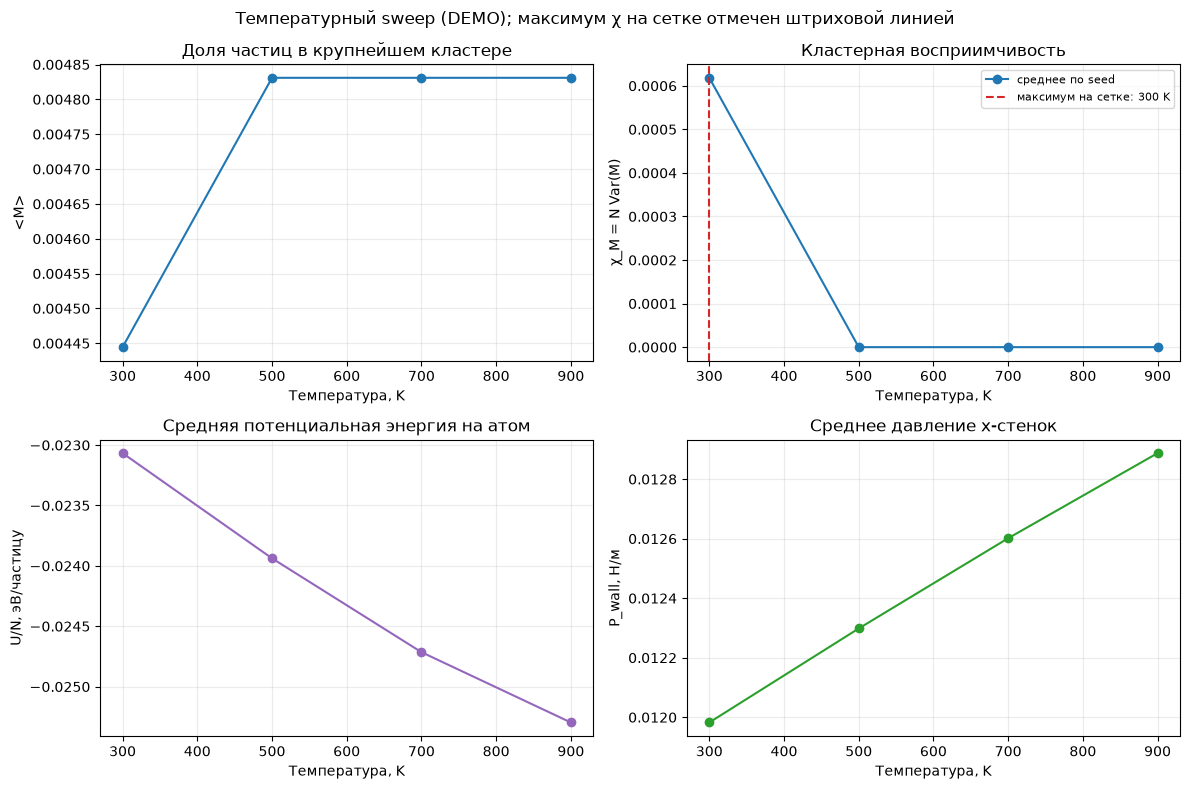

In [32]:
summary = []
for temperature in TEMPERATURES:
    group = [row for row in results if row['T'] == temperature]
    summary.append({'T': temperature,
        'M_mean': float(np.mean([row['largest_cluster_mean'] for row in group])),
        'chi_mean': float(np.mean([row['cluster_susceptibility'] for row in group])),
        'U_per_K': float(np.mean([row['potential_energy_per_particle'] for row in group])),
        'P_wall': float(np.mean([row['P_eq'] for row in group])),
        'chi_seed_std': float(np.std([row['cluster_susceptibility'] for row in group], ddof=1)) if len(group) > 1 else np.nan,
        'P_seed_std': float(np.std([row['P_eq'] for row in group], ddof=1)) if len(group) > 1 else np.nan})
transition_index = int(np.argmax([row['chi_mean'] for row in summary]))
transition_temperature = summary[transition_index]['T']

table_lines = ['| T, K | <M> | χ_M | U/N, Дж/частицу | P стенки, Н/м | SD χ между seed |', '|---:|---:|---:|---:|---:|---:|']
for row in summary:
    chi_sd = '—' if np.isnan(row['chi_seed_std']) else f"{row['chi_seed_std']:.3g}"
    table_lines.append(f"| {row['T']:.0f} | {row['M_mean']:.4f} | {row['chi_mean']:.4g} | {row['U_per_K']:.4e} | {row['P_wall']:.4e} | {chi_sd} |")
display(Markdown('\n'.join(table_lines)))

temperature_values = np.asarray([row['T'] for row in summary])
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].plot(temperature_values, [r['M_mean'] for r in summary], 'o-')
axes[0, 0].set(title='Доля частиц в крупнейшем кластере', xlabel='Температура, K', ylabel='<M>')
axes[0, 1].plot(temperature_values, [r['chi_mean'] for r in summary], 'o-', label='среднее по seed')
chi_errors = np.asarray([r['chi_seed_std'] for r in summary])
if len(SEEDS) > 1: axes[0, 1].errorbar(temperature_values, [r['chi_mean'] for r in summary], yerr=chi_errors, fmt='none', capsize=3, color='black', label='SD между seed')
axes[0, 1].axvline(transition_temperature, color='tab:red', linestyle='--', label=f'максимум на сетке: {transition_temperature:.0f} K')
axes[0, 1].set(title='Кластерная восприимчивость', xlabel='Температура, K', ylabel='χ_M = N Var(M)'); axes[0, 1].legend(fontsize=8)
axes[1, 0].plot(temperature_values, [r['U_per_K'] / 1.602176634e-19 for r in summary], 'o-', color='tab:purple')
axes[1, 0].set(title='Средняя потенциальная энергия на атом', xlabel='Температура, K', ylabel='U/N, эВ/частицу')
axes[1, 1].plot(temperature_values, [r['P_wall'] for r in summary], 'o-', color='tab:green')
axes[1, 1].set(title='Среднее давление x-стенок', xlabel='Температура, K', ylabel='P_wall, Н/м')
for axis in axes.flat: axis.grid(alpha=0.25)
fig.suptitle(f'Температурный sweep ({MODE}); максимум χ на сетке отмечен штриховой линией')
fig.tight_layout(); plt.show()


#### Интерпретация, диапазон и неопределённость

Газоподобное поведение ожидается при меньшей средней доле крупнейшего кластера; при охлаждении доля и притяжательная энергия могут указывать на объединение частиц. Пик $\chi_M$ показывает температуры, где флуктуации кластера максимальны, и служит выбранным структурным маркером. При грубой сетке можно назвать только температурную точку сетки и интервал между соседними исследованными значениями как разрешение поиска. Если максимум на краю диапазона, sweep не локализовал его — нужно расширить диапазон, а не экстраполировать.

Seed-to-seed разброс показывает чувствительность к начальным условиям; временные выборки внутри одного seed также коррелированы. Для более сильного вывода нужны больше независимых начальных состояний, длиннее equilibration/production, более мелкий шаг температуры, анализ размера системы и проверка кластерного порога. Температура определяется рескейлингом при подготовке, а не непрерывно поддерживается в production. Ни точность до одного значения T, ни кипение реального K эти вычисления не устанавливают.

In [33]:
output_dir = PROJECT_ROOT / 'output' / 'notebooks' / 'task4_phase'
output_dir.mkdir(parents=True, exist_ok=True)
names = list(results[0])
np.savetxt(output_dir / 'phase_sweep.csv', np.asarray([[row[name] for name in names] for row in results]), delimiter=',', header=','.join(names), comments='')
if len(SEEDS) > 1:
    transition_by_seed = []
    for seed in SEEDS:
        seed_rows = [row for row in results if row['seed'] == seed]
        transition_by_seed.append(max(seed_rows, key=lambda row: row['cluster_susceptibility'])['T'])
    seed_range = f'{min(transition_by_seed):.0f}–{max(transition_by_seed):.0f} K (разброс оценок по seed)'
else:
    seed_range = 'не оценён: в запуске только один seed'
edge_note = 'Максимум на краю сетки: диапазон недостаточен для локализации.' if transition_index in (0, len(summary)-1) else 'Максимум расположен внутри исследованной сетки.'
display(Markdown(f'**Итог ({MODE}):** максимум кластерной восприимчивости получен при T = {transition_temperature:.0f} K на выбранной сетке. {edge_note} Диапазон оценок seed: {seed_range}. Это структурный crossover данной конечной 2D LJTS-модели, а не экспериментальная температура фазового перехода калия. Параметры: {len(TEMPERATURES)} температур, {len(SEEDS)} seed, термализация {EQUIL_STEPS} шагов и production {PRODUCTION_STEPS} шагов на точку.'))
print(f'Результаты CSV: {output_dir.relative_to(PROJECT_ROOT) / "phase_sweep.csv"}')


**Итог (DEMO):** максимум кластерной восприимчивости получен при T = 300 K на выбранной сетке. Максимум на краю сетки: диапазон недостаточен для локализации. Диапазон оценок seed: не оценён: в запуске только один seed. Это структурный crossover данной конечной 2D LJTS-модели, а не экспериментальная температура фазового перехода калия. Параметры: 4 температур, 1 seed, термализация 50 шагов и production 100 шагов на точку.

Результаты CSV: output/notebooks/task4_phase/phase_sweep.csv


### Возможные вопросы преподавателя

1. **Чем газ отличается от конденсированного состояния в этой диагностике?** В газоподобном режиме кластеры обычно меньше и доля крупнейшего кластера ниже; при притяжении формируется крупное объединение.
2. **Почему в двумерной конечной системе переход размыт?** Размер конечен, флуктуации существенны, а строгие термодинамические особенности формируются в пределе бесконечной системы.
3. **Зачем стенки x и PBC y?** Это модель щели: стенки ограничивают поперечное движение, периодичность устраняет края вдоль канала.
4. **Что такое температурный sweep?** Набор расчётов в разных условиях температуры для построения зависимостей observables от T.
5. **Как термостатируется система?** Перед production каждые 10 шагов скорости масштабируются на $\sqrt{T_{target}/T_{measured}}$; после этого термостат выключен.
6. **Как определён кластер?** Частицы связываются ребром, если расстояние меньше $1.5\sigma$; связные компоненты находятся объединением пар.
7. **Что показывает $\chi_M$?** Насколько сильно флуктуирует доля крупнейшего кластера; пик используется как модельная метка crossover.
8. **Зачем несколько seed?** Они показывают вариацию из-за начальных координат и скоростей, которую один запуск не оценивает.
9. **Почему нельзя назвать найденное T точкой кипения калия?** Из-за конечной 2D геометрии, упрощённого LJ-потенциала, фиксированных стенок и структурного, а не термодинамического критерия.
10. **Как уточнить результат?** Увеличить число seed и длину траектории, уменьшить температурный шаг, исследовать несколько N/размеров и проверить зависимость от критерия кластера.

## Лабораторная работа 5. Неопределённость и чувствительность давления

**Цель:** оценить влияние неопределённых входов температуры $T$ и числа частиц $N$ на давление в модели работы 04, построить линейный суррогат, найти производные чувствительности и сравнить их с идеальным газом.

**Система:** K между фиксированными x-стенками и с периодическими условиями по y; выход — среднее механическое давление на x-стенки, Н/м.

**Ожидаемый результат:** таблица DOE, коэффициенты $dP/dT$ и $dP/dN$, распределение давления из Monte Carlo и сравнение с аналитическими идеальными значениями.

**Студент:** ____________________  **Группа:** __________  **Преподаватель:** ____________________

> В DEMO выполняется сокращённый расчёт на тех же 1035 частицах и на той же сетке DOE, но с короткой траекторией и одним seed. FULL запускает 3×3×3 расчётов по параметрам task5. DEMO даёт предварительную иллюстрацию, а не окончательную неопределённость.

### 1. Постановка и понятия неопределённости

**Неопределённость** описывает диапазон результатов, возникающий из-за неизвестности/вариации входов и случайности оценивания. **Чувствительность** описывает изменение выхода при малом изменении конкретного входа. Большая чувствительность не всегда означает большую неопределённость: важны и величина входного диапазона, и неопределённость модели.

Задание задаёт $T=T_0\pm10\%$ и $N=N_0\pm5\%$. Формируем DOE — план вычислительного эксперимента — на сетке $T=\{0.9T_0,T_0,1.1T_0\}$ и $N=\{round(0.95N_0),N_0,round(1.05N_0)\}$. Для каждой пары выполняются повторы с независимыми фиксированными seed. Затем по выходам подгоняется локальный линейный суррогат
$$P(T,N)=a+bT+cN,\qquad \frac{\partial P}{\partial T}=b,\quad \frac{\partial P}{\partial N}=c.$$

$a$ имеет единицы Н/м, $b$ — Н/(м·K), $c$ — Н/м на одну частицу (число частиц формально безразмерно). Суррогат приближает результаты MD только в выбранном диапазоне и проверяется по остаткам, $R^2$ и RMSE. Коэффициент $b$ показывает локальное изменение давления при фиксированном N; $c$ — при фиксированной T.

Для идеального двумерного газа $P_{ideal}=Nk_BT/A$, поэтому $\partial P/\partial T=Nk_B/A$ и $\partial P/\partial N=k_BT/A$. Это сравнительный аналитический ориентир. MD учитывает взаимодействия K–K и стенки, использует механическое давление и конечную коррелированную траекторию, поэтому значения могут отличаться.

Изменение N проводится в неизменной площади коробки. Следовательно, вместе с числом частиц меняется поверхностная плотность $N/A$; коэффициент $c$ нельзя трактовать как эффект добавления атома при неизменной концентрации. Число N физически целое, хотя Monte Carlo ниже непрерывно сэмплирует N как приближение локальной линейной модели.

Параметры K, $T_0=1173.15$ K и размер 24 нм происходят из варианта задания. K–K LJTS — учебное фиксированное приближение без найденной в репозитории точной библиографической ссылки; ограничения LJ для реального калия обсуждаются в Eslami et al., 2010, DOI [10.1007/bf03246015](https://doi.org/10.1007/bf03246015). Условия стенок и алгоритм такие же, как в работе 04.

#### Исходные данные DOE

| Параметр | Номинал / FULL | Единица | Примечание |
|---|---:|---|---|
| Температура $T_0$ | 1173.15 | K | 900 °C + 273.15 |
| Диапазон T | 1055.835–1290.465 | K | ±10%; DOE: 3 уровня |
| Число частиц $N_0$ | 1035 | атомов | Вариант задания |
| Диапазон N | 983–1087 | атомов | ±5%; округлено до целых в MD DOE |
| Площадь | 576 | нм² | Коробка 24×24 нм; не изменяется при варьировании N |
| Seed | 7, 17, 27 | — | FULL: три повтора на каждую из девяти пар |
| Термализация / production | 2000 / 4000 | шагов | $\Delta t=1$ фс; sample interval 20 шагов |
| Выход | среднее давления x-стенок | Н/м | Не Па: сила делится на длину стенки |
| Monte Carlo | 100 000 | выборок | $T$ и $N$ семплируются независимо и равномерно |

При пересчёте единиц энергии $\varepsilon=850k_B$ — Дж на взаимодействующую пару, а энергия на моль получается умножением на $N_A$. Эквивалентное 3D-давление получают только при дополнительном делении на принятую толщину $z$.

### 2. План DOE, режим и единицы

`np.array` создаёт числовой массив температур; `round` округляет число атомов до целого. Списки seed определяют повторные реализации случайных начальных условий. Функция ядра `run_simulation(T, N, config, ...)` получает пару входов, конфигурацию щелевого канала и длины этапов. Внутри она создаёт движок того же MD-ядра, проводит термализацию рескейлингом скорости раз в 10 шагов, затем production без термостата и возвращает словарь `T`, `N`, `seed`, среднего давления `P_eq`, временного разброса `P_std`, оценки `P_sem` и времени термализации. Здесь `P_eq` — имя поля для среднего production давления, а не самостоятельное подтверждение равновесия. Аргумент `sample_interval` означает шаг между сохранёнными значениями давления, а не временной шаг интегратора. Повторы нужны, чтобы оценить разброс от seed; они не устраняют корреляции временных точек.

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import replace
from IPython.display import Markdown, display

MODE = 'DEMO'  # переключите на FULL, чтобы выполнить исходный вычислительный план
N0 = 1035
T0 = TEMPERATURE_K
TEMPERATURES = np.array([0.9 * T0, T0, 1.1 * T0])
PARTICLE_COUNTS = [round(0.95 * N0), N0, round(1.05 * N0)]
if MODE == 'DEMO': SEEDS, EQUIL_STEPS, PRODUCTION_STEPS, SAMPLE_EVERY = [7], 20, 60, 10
elif MODE == 'FULL': SEEDS, EQUIL_STEPS, PRODUCTION_STEPS, SAMPLE_EVERY = [7, 17, 27], 2_000, 4_000, 20
else: raise ValueError("MODE должен быть DEMO или FULL")
base_config = default_config(force_backend='cell_list', periodic_x=False, periodic_y=True, wall_mode='x')
print(f'{MODE}: T0={T0:.2f} K, диапазон T={TEMPERATURES[0]:.2f}…{TEMPERATURES[-1]:.2f} K; N={PARTICLE_COUNTS} в площади {base_config.box.area * 1e18:.2f} нм²; seeds={SEEDS}; equil={EQUIL_STEPS}, production={PRODUCTION_STEPS} шагов')


DEMO: T0=1173.15 K, диапазон T=1055.84…1290.47 K; N=[983, 1035, 1087] в площади 576.00 нм²; seeds=[7]; equil=20, production=60 шагов


### 3. Выполняем вычислительный план

Два цикла `for` перебирают все значения температуры и количества частиц; третий цикл повторяет каждую пару для разных seed. Вызов `run_simulation` возвращает один словарь с результатом, который добавляется в список `results`. Список удобен для последовательных записей разного запуска; словарь даёт доступ к значению по понятному ключу, например `row['P_eq']`. В DEMO изменена только длина траектории и число повторов, а диапазоны T/N и размер 1035 в центре сохранены и явно напечатаны. Каждая рассчитанная строка содержит среднее давления механической реакции стенок в Н/м, а не давление в паскалях.

In [35]:
results = []
for temperature in TEMPERATURES:
    for particle_count in PARTICLE_COUNTS:
        for seed in SEEDS:
            run_config = replace(base_config, seed=seed)  # задаём отдельное начальное состояние повтора
            row = run_simulation(temperature, particle_count, run_config,
                equilibration_steps=EQUIL_STEPS, production_steps=PRODUCTION_STEPS,
                sample_interval=SAMPLE_EVERY)
            row['seed'] = seed  # фиксируем seed именно этого повтора в таблице
            results.append(row)
            print(row)
print(f'Всего DOE-точек с повторами: {len(results)}; уникальных сочетаний T,N: {len(TEMPERATURES) * len(PARTICLE_COUNTS)}')


{'T': 1055.835, 'N': 983, 'seed': 7, 'P_eq': 0.009352852051773703, 'P_std': 5.716596322179871e-05, 'P_sem': 2.3337906758019392e-05, 'equilibration_time': 2.0000000000000003e-14}


{'T': 1055.835, 'N': 1035, 'seed': 7, 'P_eq': 0.011975282359030543, 'P_std': 0.0002664809198461181, 'P_sem': 0.00010879037996841542, 'equilibration_time': 2.0000000000000003e-14}


{'T': 1055.835, 'N': 1087, 'seed': 7, 'P_eq': 0.013255234713134572, 'P_std': 0.0004517444349494066, 'P_sem': 0.00018442389329465902, 'equilibration_time': 2.0000000000000003e-14}


{'T': 1173.15, 'N': 983, 'seed': 7, 'P_eq': 0.009367937385058521, 'P_std': 7.045904208834485e-05, 'P_sem': 2.8764783480288162e-05, 'equilibration_time': 2.0000000000000003e-14}


{'T': 1173.15, 'N': 1035, 'seed': 7, 'P_eq': 0.012024056784041115, 'P_std': 0.0002930012754746103, 'P_sem': 0.00011961726981624105, 'equilibration_time': 2.0000000000000003e-14}


{'T': 1173.15, 'N': 1087, 'seed': 7, 'P_eq': 0.01333482456063144, 'P_std': 0.0004963802849746745, 'P_sem': 0.00020264640276087604, 'equilibration_time': 2.0000000000000003e-14}


{'T': 1290.4650000000001, 'N': 983, 'seed': 7, 'P_eq': 0.009382682518616773, 'P_std': 8.58768371366369e-05, 'P_sem': 3.50590719514756e-05, 'equilibration_time': 2.0000000000000003e-14}


{'T': 1290.4650000000001, 'N': 1035, 'seed': 7, 'P_eq': 0.012071940630489747, 'P_std': 0.0003201181401538001, 'P_sem': 0.00013068768346426022, 'equilibration_time': 2.0000000000000003e-14}


{'T': 1290.4650000000001, 'N': 1087, 'seed': 7, 'P_eq': 0.013415554245037256, 'P_std': 0.0005406679135452291, 'P_sem': 0.0002207267514135035, 'equilibration_time': 2.0000000000000003e-14}
Всего DOE-точек с повторами: 9; уникальных сочетаний T,N: 9


### 4. Линейный суррогат и производные

`fit_linear_surrogate(results)` превращает колонки `T`, `N`, `P_eq` в NumPy-массивы, формирует матрицу с колонками $1,T,N$ и решает задачу наименьших квадратов через `np.linalg.lstsq`. Возвращаемый словарь содержит коэффициенты $a,b,c$, предсказания и остатки для каждой точки, $R^2$, RMSE и наибольший остаток. Коэффициенты `b_dP_dT` и `c_dP_dN` интерпретируются как производные только в ограниченном DOE-диапазоне. Сходимость идеальной плоскости к точкам и величины остатков показывают, насколько линейное приближение здесь приемлемо.

P(T,N) = a + bT + cN, a = -2.83855e-02 Н/м
dP/dT = b = 4.07462e-07 Н/(м·K)
dP/dN = c = 3.81479e-05 Н/м на частицу
R² = 0.96298; RMSE = 3.17645e-04 Н/м; максимальный остаток = 4.48543e-04 Н/м


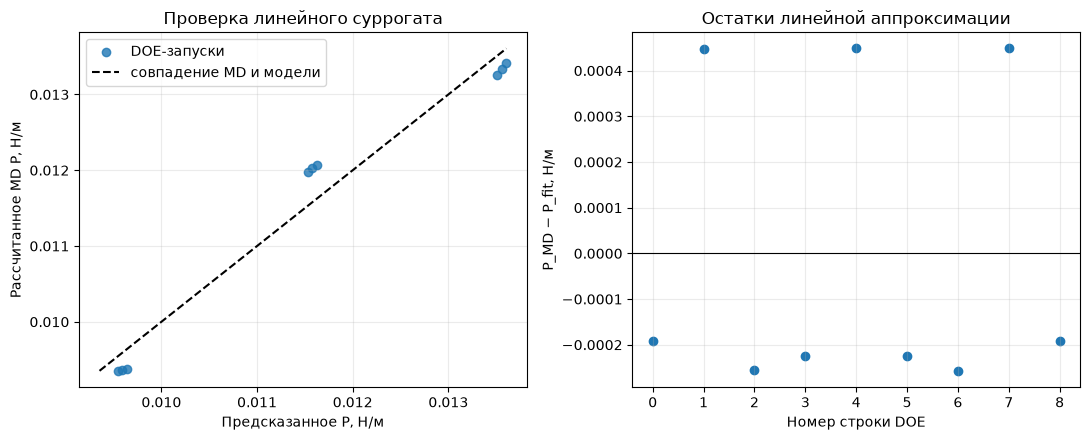

In [36]:
coefficients = fit_linear_surrogate(results)
a = coefficients['a']
dP_dT = coefficients['b_dP_dT']
dP_dN = coefficients['c_dP_dN']
pressure_observed = np.asarray([row['P_eq'] for row in results])
pressure_predicted = np.asarray(coefficients['predicted'])
print(f'P(T,N) = a + bT + cN, a = {a:.5e} Н/м')
print(f'dP/dT = b = {dP_dT:.5e} Н/(м·K)')
print(f'dP/dN = c = {dP_dN:.5e} Н/м на частицу')
print(f'R² = {coefficients["r_squared"]:.5f}; RMSE = {coefficients["rmse"]:.5e} Н/м; максимальный остаток = {coefficients["max_abs_residual"]:.5e} Н/м')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(pressure_predicted, pressure_observed, alpha=0.8, label='DOE-запуски')
low = min(np.min(pressure_predicted), np.min(pressure_observed)); high = max(np.max(pressure_predicted), np.max(pressure_observed))
axes[0].plot([low, high], [low, high], 'k--', label='совпадение MD и модели')
axes[0].set(title='Проверка линейного суррогата', xlabel='Предсказанное P, Н/м', ylabel='Рассчитанное MD P, Н/м'); axes[0].legend()
residuals = pressure_observed - pressure_predicted
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].scatter(np.arange(len(residuals)), residuals)
axes[1].set(title='Остатки линейной аппроксимации', xlabel='Номер строки DOE', ylabel='P_MD − P_fit, Н/м')
for axis in axes: axis.grid(alpha=0.25)
fig.tight_layout(); plt.show()


#### Аналитический идеальный газ и чувствительность

При фиксированной площади двумерного слоя $P_{ideal}=Nk_BT/A$. Его производные находятся аналитически: $Nk_B/A$ по температуре и $k_BT/A$ по числу частиц. Единицы — соответственно Н/(м·K) и Н/м на единицу N. Сравнение помогает понять не только значения давления, но и вклад взаимодействий/стенок. Поскольку модельная observable — механическое давление x-стенки, а идеальная формула предполагает однородную равновесную систему, различия ожидаемы и не означают автоматически ошибку программы.

In [37]:
area = base_config.box.area
ideal_pressure_2d = N0 * BOLTZMANN * T0 / area
ideal_pressure_3d = ideal_pressure_2d / LAYER_THICKNESS
ideal_dP_dT = N0 * BOLTZMANN / area
ideal_dP_dN = BOLTZMANN * T0 / area
nominal_pressures = [row['P_eq'] for row in results if row['T'] == T0 and row['N'] == N0]
md_nominal_pressure = float(np.mean(nominal_pressures))

comparison = [
    ('Номинальное P_MD', md_nominal_pressure, 'Н/м'),
    ('Идеальное 2D P', ideal_pressure_2d, 'Н/м'),
    ('Идеальное эквивалентное 3D P', ideal_pressure_3d, 'Па'),
    ('Суррогат dP/dT', dP_dT, 'Н/(м·K)'),
    ('Идеальный dP/dT', ideal_dP_dT, 'Н/(м·K)'),
    ('Суррогат dP/dN', dP_dN, 'Н/м на частицу'),
    ('Идеальный dP/dN', ideal_dP_dN, 'Н/м на частицу'),
]
table = ['| Показатель | Значение | Единица |', '|---|---:|---|']
for name, value, unit in comparison: table.append(f'| {name} | {value:.6e} | {unit} |')
display(Markdown('\n'.join(table)))
print(f'Разница номинального MD давления от идеального 2D: {abs(md_nominal_pressure - ideal_pressure_2d):.5e} Н/м')
print(f'При пересчёте на моль: 1 Дж/частицу × N_A = Дж/моль; при пересчёте слоевого P₂D в Па дополнительно делим на z={LAYER_THICKNESS * 1e9:.3f} нм.')


| Показатель | Значение | Единица |
|---|---:|---|
| Номинальное P_MD | 1.202406e-02 | Н/м |
| Идеальное 2D P | 2.910413e-02 | Н/м |
| Идеальное эквивалентное 3D P | 3.901441e+07 | Па |
| Суррогат dP/dT | 4.074618e-07 | Н/(м·K) |
| Идеальный dP/dT | 2.480854e-05 | Н/(м·K) |
| Суррогат dP/dN | 3.814789e-05 | Н/м на частицу |
| Идеальный dP/dN | 2.811994e-05 | Н/м на частицу |

Разница номинального MD давления от идеального 2D: 1.70801e-02 Н/м
При пересчёте на моль: 1 Дж/частицу × N_A = Дж/моль; при пересчёте слоевого P₂D в Па дополнительно делим на z=0.746 нм.


### 5. Перенос неопределённости методом Monte Carlo

`propagate_uniform_uncertainty` создаёт воспроизводимый генератор `np.random.default_rng(seed)` и 100 000 независимых пар $(T,N)$ из равномерных диапазонов задания. Для каждой пары функция вычисляет давление линейного суррогата и возвращает массив samples, среднее, стандартное отклонение и 2.5/97.5 процентили. Это выборочное распространение **входной** неопределённости через суррогат. Оно не включает ошибку подгонки, автокорреляцию MD и межseed вариацию, если не моделировать их отдельно. Из-за линейного суррогата continuous N — математическое приближение, хотя физические расчёты DOE используют целые N. Фиксированный Monte Carlo seed обеспечивает повторяемость самого семплирования.

Среднее P по Monte Carlo: 1.15768e-02 Н/м
SD P только из заданных входных диапазонов: 1.13896e-03 Н/м
95%-й центральный интервал суррогата: [9.70513e-03, 1.34494e-02] Н/м
Линейная оценка SD при независимых равномерных T,N: 1.14011e-03 Н/м


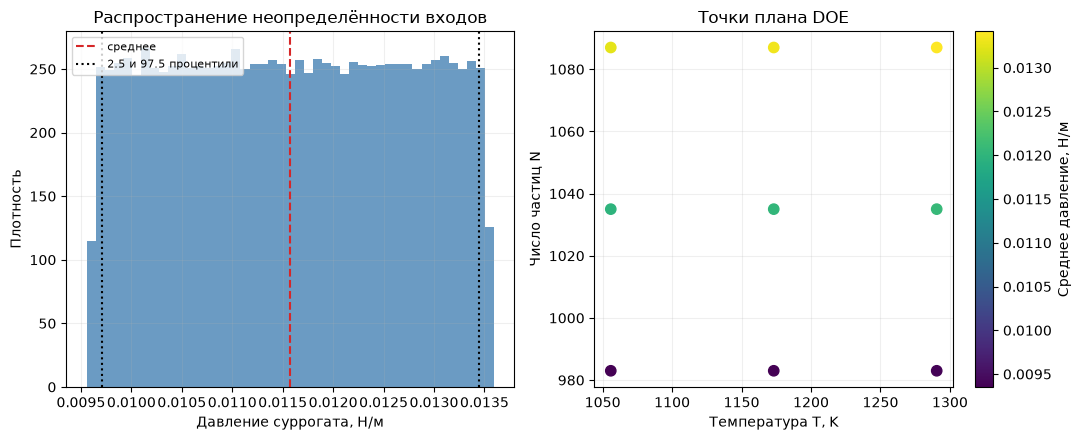

In [38]:
uncertainty = propagate_uniform_uncertainty(coefficients, T0, N0, samples=100_000, seed=2027)
temperature_std_input = (0.2 * T0) / np.sqrt(12)  # SD равномерной величины ширины 0.2*T0
particle_std_input = (0.1 * N0) / np.sqrt(12)
linearized_pressure_std = np.sqrt((dP_dT * temperature_std_input)**2 + (dP_dN * particle_std_input)**2)
print(f'Среднее P по Monte Carlo: {uncertainty["P_mean"]:.5e} Н/м')
print(f'SD P только из заданных входных диапазонов: {uncertainty["P_std"]:.5e} Н/м')
print(f'95%-й центральный интервал суррогата: [{uncertainty["P_q025"]:.5e}, {uncertainty["P_q975"]:.5e}] Н/м')
print(f'Линейная оценка SD при независимых равномерных T,N: {linearized_pressure_std:.5e} Н/м')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].hist(uncertainty['samples'], bins=45, density=True, color='steelblue', alpha=0.8)
axes[0].axvline(uncertainty['P_mean'], color='tab:red', linestyle='--', label='среднее')
axes[0].axvline(uncertainty['P_q025'], color='black', linestyle=':', label='2.5 и 97.5 процентили')
axes[0].axvline(uncertainty['P_q975'], color='black', linestyle=':')
axes[0].set(title='Распространение неопределённости входов', xlabel='Давление суррогата, Н/м', ylabel='Плотность'); axes[0].legend(fontsize=8)
scatter = axes[1].scatter([row['T'] for row in results], [row['N'] for row in results], c=[row['P_eq'] for row in results], cmap='viridis', s=55)
axes[1].set(title='Точки плана DOE', xlabel='Температура T, K', ylabel='Число частиц N')
fig.colorbar(scatter, ax=axes[1], label='Среднее давление, Н/м')
for axis in axes: axis.grid(alpha=0.2)
fig.tight_layout(); plt.show()


#### Вывод об неопределённости и границы вывода

Ширина гистограммы определяется чувствительностью суррогата и заданными диапазонами T/N. При независимых равномерных входах линеаризованная дисперсия равна $\sigma_P^2\approx b^2\sigma_T^2+c^2\sigma_N^2$; близость её к Monte Carlo SD проверяет внутреннюю согласованность линейного суррогата. Она не является полной неопределённостью физического предсказания. Для её расширения потребовались бы остаточная/параметрическая неопределённость суррогата, статистическая неопределённость MD и модельная ошибка.

Давление не обязано совпадать с идеальным газом: взаимодействия меняют вириальный/стеночный вклад, возможна неоднородность возле стенок, а симуляция конечна и статистически ограничена. Линейность проверяется остатками и областью DOE; за диапазон ±10% T и ±5% N не следует экстраполировать. При фиксированной площади N изменяет поверхностную плотность.

In [39]:
output_dir = PROJECT_ROOT / 'output' / 'notebooks' / 'task5_uq'
output_dir.mkdir(parents=True, exist_ok=True)
column_names = list(results[0])
np.savetxt(output_dir / 'doe_results.csv', np.asarray([[row[name] for name in column_names] for row in results]), delimiter=',', header=','.join(column_names), comments='')
nominal_difference = abs(md_nominal_pressure - ideal_pressure_2d)
nominal_relative_percent = 100 * nominal_difference / abs(ideal_pressure_2d)
display(Markdown(f'**Вывод ({MODE}):** рассчитано {len(results)} запусков DOE при T = {TEMPERATURES.min():.1f}…{TEMPERATURES.max():.1f} K и N = {min(PARTICLE_COUNTS)}…{max(PARTICLE_COUNTS)} в фиксированной площади {area * 1e18:.1f} нм². Локальная оценка чувствительности: $dP/dT={dP_dT:.4e}$ Н/(м·K), $dP/dN={dP_dN:.4e}$ Н/м на частицу. Линейная модель: $R^2={coefficients["r_squared"]:.4f}$, RMSE={coefficients["rmse"]:.3e} Н/м. По входным диапазонам получено среднее $P={uncertainty["P_mean"]:.4e}$ Н/м, SD={uncertainty["P_std"]:.3e} Н/м, центральный 95%-й интервал [{uncertainty["P_q025"]:.4e}, {uncertainty["P_q975"]:.4e}] Н/м. Номинальное MD давление отличается от идеального 2D ориентира на {nominal_relative_percent:.2f}%. Значения относятся к {MODE}; DEMO не является окончательной статистической оценкой.'))
print(f'Результаты DOE сохранены в {output_dir.relative_to(PROJECT_ROOT) / "doe_results.csv"}')


**Вывод (DEMO):** рассчитано 9 запусков DOE при T = 1055.8…1290.5 K и N = 983…1087 в фиксированной площади 576.0 нм². Локальная оценка чувствительности: $dP/dT=4.0746e-07$ Н/(м·K), $dP/dN=3.8148e-05$ Н/м на частицу. Линейная модель: $R^2=0.9630$, RMSE=3.176e-04 Н/м. По входным диапазонам получено среднее $P=1.1577e-02$ Н/м, SD=1.139e-03 Н/м, центральный 95%-й интервал [9.7051e-03, 1.3449e-02] Н/м. Номинальное MD давление отличается от идеального 2D ориентира на 58.69%. Значения относятся к DEMO; DEMO не является окончательной статистической оценкой.

Результаты DOE сохранены в output/notebooks/task5_uq/doe_results.csv


### Возможные вопросы преподавателя

1. **Что такое чувствительность?** Наклон выхода по входу при фиксированных остальных параметрах: здесь $dP/dT$ и $dP/dN$.
2. **Чем чувствительность отличается от неопределённости?** Чувствительность — производная; неопределённость — распределение возможных выходов из-за диапазонов входов и других источников ошибки.
3. **Что такое DOE?** Заранее заданная сетка комбинаций параметров, позволяющая систематически изучить выход и оценить приближение.
4. **Зачем несколько seed?** Чтобы увидеть variation от разных начальных координат и скоростей, а не полагаться на один случайный старт.
5. **Что делает `run_simulation`?** Для одной пары T,N использует MD-движок, готовит систему рескейлингом скорости и усредняет wall pressure на production-участке.
6. **Что означает коэффициент $b$?** Приближённое изменение давления на один кельвин при фиксированном числе частиц; единицы Н/(м·K).
7. **Что означает $c$?** Локальное изменение давления при добавлении одной частицы в фиксированную площадь; вместе с N меняется плотность.
8. **Почему линейный surrogate не универсален?** Он подогнан на конечной сетке и может плохо описывать нелинейность за её пределами; проверяйте остатки и $R^2$.
9. **Что показывает Monte Carlo histogram?** Распределение давления суррогата при заданных равномерных диапазонах независимых входов, не полную ошибку модели.
10. **Почему MD отличается от идеального газа?** В MD есть межчастичные силы и стеночное взаимодействие; плюс конечная система и статистическая ошибка.